# Baru - FOR 41 Datasets

"""
Audit-ready N-LDF benchmark for the 41 KEEL datasets (Enhanced Version).

Improvements:
* Checkpoint/resume capability
* Graceful degradation for dataset failures
* Bootstrap confidence intervals
* Effect size calculations
* Complete pairwise statistical comparisons
* Separate cache directory
* Warm-up runs for JIT compilers
* Global timeouts
* More robust encoding handling
"""



In [ ]:
# Cell 0 (TAMBAHKAN DI AWAL, SEBELUM CELL 1)
"""Cell 0: Install Required Packages"""
!pip install -q imbalanced-learn xgboost scikit-posthocs requests tqdm
print("✅ All packages installed!")

# Mount Google Drive untuk menyimpan hasil
from google.colab import drive
drive.mount('/content/drive')

# Ubah output dir ke Google Drive
output_dir = '/content/drive/MyDrive/nldf_results_41'

✅ All packages installed!
Mounted at /content/drive


### Cell 1: Import dan Constants

In [ ]:
"""Cell 1 (REVISED): Import dan Constants dengan KDD Cup Fix"""

from __future__ import annotations

import argparse
import hashlib
import importlib.metadata
import io
import json
import pickle
import platform
import re
import signal
import sys
import time
import zipfile
import warnings
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Callable, Optional

import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from tqdm import tqdm
from urllib3.util.retry import Retry

warnings.filterwarnings('ignore')

# Optional dependencies
try:
    from imblearn.combine import SMOTETomek
    from imblearn.over_sampling import ADASYN, BorderlineSMOTE, SMOTE
except ImportError:
    SMOTETomek = ADASYN = BorderlineSMOTE = SMOTE = None

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

try:
    import scikit_posthocs as sp
except ImportError:
    sp = None

# Constants
RANDOM_STATE = 42
METHODS = ("Baseline", "SMOTE", "B-SMOTE", "ADASYN", "SMOTE-Tomek", "N-LDF")
CLASSIFIERS = ("RF", "SVM-Linear", "SVM-RBF", "XGBoost")
GLOBAL_TIMEOUT = 3600

# FIXED DATASETS: Remove problematic URLs, use alternative sources
DATASETS: dict[str, str] = {
    # Mild imbalance
    "glass1": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/glass1.zip",
    "pima": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/pima.zip",
    "iris0": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/iris0.zip",
    "yeast1": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/yeast1.zip",
    "haberman": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/haberman.zip",
    "vehicle1": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/vehicle1.zip",
    "ecoli1": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/ecoli1.zip",
    "ecoli2": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/ecoli2.zip",
    "segment0": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/segment0.zip",
    "yeast3": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/yeast3.zip",

    # High imbalance
    "yeast-2_vs_4": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/yeast-2_vs_4.zip",
    "vowel0": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/vowel0.zip",
    "glass4": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/glass4.zip",
    "ecoli4": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/ecoli4.zip",
    "abalone9-18": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/abalone9-18.zip",
    "yeast-1-4-5-8_vs_7": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/yeast-1-4-5-8_vs_7.zip",
    "glass5": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/glass5.zip",
    "yeast-2_vs_8": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/yeast-2_vs_8.zip",
    "yeast4": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/yeast4.zip",
    "yeast-1-2-8-9_vs_7": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/yeast-1-2-8-9_vs_7.zip",
    "yeast5": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/yeast5.zip",
    "ecoli-0-1-3-7_vs_2-6": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/ecoli-0-1-3-7_vs_2-6.zip",

    # Extreme imbalance
    "abalone-21_vs_8": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/abalone-21_vs_8.zip",
    "yeast6": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/yeast6.zip",
    "winequality-white-3_vs_7": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/winequality-white-3_vs_7.zip",
    "winequality-red-8_vs_6-7": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/winequality-red-8_vs_6-7.zip",
    "abalone-19_vs_10-11-12-13": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/abalone-19_vs_10-11-12-13.zip",
    "winequality-white-3-9_vs_5": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/winequality-white-3-9_vs_5.zip",
    "poker-8-9_vs_6": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/poker-8-9_vs_6.zip",
    "shuttle-2_vs_5": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/shuttle-2_vs_5.zip",
    "winequality-red-3_vs_5": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/winequality-red-3_vs_5.zip",
    "abalone-20_vs_8-9-10": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/abalone-20_vs_8-9-10.zip",
    "poker-8-9_vs_5": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/poker-8-9_vs_5.zip",
    "poker-8_vs_6": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/poker-8_vs_6.zip",
    "abalone19": "https://sci2s.ugr.es/keel/dataset/data/imbalanced/abalone19.zip",

    # FIXED: KDD Cup datasets dengan alternative processing flag
    "kddcup-land_vs_portsweep": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/kddcup-land_vs_portsweep.zip",
    "kddcup-buffer_overflow_vs_back": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/kddcup-buffer_overflow_vs_back.zip",
    "kddcup-land_vs_satan": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/kddcup-land_vs_satan.zip",
    "kddcup-rootkit-imap_vs_back": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/kddcup-rootkit-imap_vs_back.zip",
    "kr-vs-k-zero_vs_eight": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/kr-vs-k-zero_vs_eight.zip",
    "kr-vs-k-zero_vs_fifteen": "https://sci2s.ugr.es/keel/keel-dataset/datasets/imbalanced/imb_IRhigherThan9p3/kr-vs-k-zero_vs_fifteen.zip",
}

# Flag problematic datasets yang butuh special handling
PROBLEMATIC_DATASETS = {
    "kddcup-land_vs_portsweep", "kddcup-buffer_overflow_vs_back",
    "kddcup-land_vs_satan", "kddcup-rootkit-imap_vs_back",
    "kr-vs-k-zero_vs_eight", "kr-vs-k-zero_vs_fifteen"
}

print(f"✅ Cell 1 loaded: {len(DATASETS)} datasets configured")
print(f"⚠️  Problematic datasets (special handling): {len(PROBLEMATIC_DATASETS)}")

✅ Cell 1 loaded: 41 datasets configured
⚠️  Problematic datasets (special handling): 6


### Cell 2: Classes dan Utility Functions

In [ ]:
"""Cell 2 (REVISED): Classes dengan Fixed Categorical Handling"""

@dataclass
class LoadedDataset:
    """Container for loaded dataset with metadata."""
    name: str
    X: pd.DataFrame
    y: np.ndarray
    numeric_columns: list[int]
    categorical_columns: list[int]
    n_samples: int
    n_features: int
    n_minority: int
    n_majority: int
    imbalance_ratio: float
    severity: str
    source_url: str
    sha256: str
    is_problematic: bool = False  # NEW: Flag for special handling


@dataclass
class CheckpointState:
    """State for checkpoint/resume functionality."""
    completed_datasets: set = field(default_factory=set)
    results: list[dict[str, object]] = field(default_factory=list)

    def save(self, path: Path) -> None:
        with open(path, 'wb') as f:
            pickle.dump(self, f)

    @classmethod
    def load(cls, path: Path) -> 'CheckpointState':
        with open(path, 'rb') as f:
            return pickle.load(f)


class TimeoutError(Exception):
    pass


class FoldPreprocessor:
    """FOLD-PREPROCESSOR DENGAN FIX UNTUK KDD CUP DATASETS"""

    def __init__(self, numeric_columns: list[int], categorical_columns: list[int],
                 dataset_name: str = ""):
        self.numeric_columns = numeric_columns
        self.categorical_columns = categorical_columns
        self.dataset_name = dataset_name
        self.transformer: ColumnTransformer | None = None
        self.categorical_slices: list[slice] = []
        self.original_feature_order: list[int] = []
        self.has_categorical = len(categorical_columns) > 0
        self._fitted_categories: list = []

    def fit(self, X_train: pd.DataFrame) -> "FoldPreprocessor":
        """Fit preprocessor dengan safe categorical handling."""
        transformers: list[tuple[str, Pipeline, list[int]]] = []
        self.original_feature_order = []

        # Numeric pipeline
        if self.numeric_columns:
            numeric_pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ])
            transformers.append(("numeric", numeric_pipeline, self.numeric_columns))
            self.original_feature_order.extend(self.numeric_columns)

        # Categorical pipeline dengan FIX
        if self.categorical_columns:
            # Hanya proses kolom kategorikal yang valid
            valid_cat_cols = []
            for col in self.categorical_columns:
                if col < X_train.shape[1]:
                    n_unique = X_train.iloc[:, col].nunique()
                    # Skip jika terlalu banyak kategori (KDD Cup issue)
                    if n_unique < min(100, len(X_train) * 0.5):
                        valid_cat_cols.append(col)
                    else:
                        # Treat as numeric instead
                        if col not in self.numeric_columns:
                            self.numeric_columns.append(col)

            if valid_cat_cols:
                try:
                    encoder = OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False,
                        dtype=float,
                        max_categories=50  # LIMIT categories untuk KDD Cup
                    )
                except TypeError:
                    encoder = OneHotEncoder(
                        handle_unknown="ignore",
                        sparse=False,
                        dtype=float
                    )

                categorical_pipeline = Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", encoder),
                ])
                transformers.append(("categorical", categorical_pipeline, valid_cat_cols))
                self.original_feature_order.extend(valid_cat_cols)
                self.categorical_columns = valid_cat_cols  # Update dengan yang valid saja

        if not transformers:
            # Fallback: semua kolom sebagai numerik
            all_cols = list(range(X_train.shape[1]))
            numeric_pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ])
            transformers.append(("numeric", numeric_pipeline, all_cols))
            self.numeric_columns = all_cols
            self.categorical_columns = []
            self.has_categorical = False

        self.transformer = ColumnTransformer(transformers, remainder="drop", sparse_threshold=0)
        self.transformer.fit(X_train)

        # Build categorical slices SAFELY
        self.categorical_slices = []
        if self.has_categorical and self.categorical_columns:
            try:
                if hasattr(self.transformer, 'transformers_'):
                    feature_idx = 0
                    for name, _, cols in self.transformer.transformers_:
                        if name == "numeric":
                            feature_idx += len(cols)
                        elif name == "categorical":
                            cat_transformer = self.transformer.named_transformers_["categorical"]
                            encoder = cat_transformer.named_steps["onehot"]
                            if hasattr(encoder, 'categories_'):
                                for categories in encoder.categories_:
                                    n_cats = len(categories)
                                    if n_cats > 0:  # Skip empty categories
                                        self.categorical_slices.append(
                                            slice(feature_idx, feature_idx + n_cats)
                                        )
                                        feature_idx += n_cats
            except Exception as e:
                # Jika gagal, treat all as numeric
                self.has_categorical = False
                self.categorical_slices = []

        return self

    def transform(self, X: pd.DataFrame) -> np.ndarray:
        """Transform data safely."""
        if self.transformer is None:
            raise RuntimeError("FoldPreprocessor must be fitted before transform")
        try:
            return np.asarray(self.transformer.transform(X), dtype=float)
        except Exception as e:
            # Fallback: hanya gunakan kolom numerik
            if self.numeric_columns:
                return np.asarray(X.iloc[:, self.numeric_columns], dtype=float)
            else:
                return np.asarray(X, dtype=float)

    def project_categorical(self, X: np.ndarray) -> np.ndarray:
        """FIXED: Project categorical dengan empty array handling."""
        if not self.has_categorical or not self.categorical_slices:
            return np.asarray(X, dtype=float)

        projected = np.asarray(X, dtype=float).copy()

        for block in self.categorical_slices:
            # SAFETY CHECKS
            if block.start >= projected.shape[1]:
                continue
            if block.stop > projected.shape[1]:
                continue

            values = projected[:, block]
            if values.size == 0 or values.shape[1] == 0:
                continue

            try:
                winners = np.argmax(values, axis=1)
                values[:] = 0.0
                values[np.arange(len(values)), winners] = 1.0
                projected[:, block] = values
            except (ValueError, IndexError):
                # Jika gagal, biarkan values apa adanya
                continue

        return projected


# Copy semua fungsi utility yang sama (timeout_handler, stable_seed, dll)
def timeout_handler(signum, frame):
    raise TimeoutError("Dataset processing timed out")

def stable_seed(*parts: object, base: int = RANDOM_STATE) -> int:
    payload = "|".join(map(str, (base, *parts))).encode("utf-8")
    return int.from_bytes(hashlib.sha256(payload).digest()[:4], "little")

def severity_from_ir(ir: float) -> str:
    if ir < 9:
        return "Mild"
    if ir < 40:
        return "High"
    return "Extreme"

def make_http_session() -> requests.Session:
    retry = Retry(total=3, connect=3, read=3, backoff_factor=1.0,
                  status_forcelist=(429, 500, 502, 503, 504),
                  allowed_methods=("GET",))
    session = requests.Session()
    session.mount("https://", HTTPAdapter(max_retries=retry))
    session.headers.update({"User-Agent": "NLDF-reproducibility-study/1.0"})
    return session

def parse_attribute_type(line: str) -> bool:
    lowered = line.lower()
    return bool(re.search(r"\b(real|integer|numeric)\b", lowered))

def effective_k(y_train: np.ndarray, requested: int = 5) -> int:
    n_minority = int((y_train == 1).sum())
    if n_minority < 2:
        raise ValueError("At least two training minority observations are required")
    return min(requested, n_minority - 1)

def evaluate_predictions(y_true: np.ndarray, y_pred: np.ndarray, y_score: np.ndarray) -> dict[str, float]:
    sensitivity = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    specificity = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
    return {
        "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": sensitivity,
        "Specificity": specificity,
        "G-Mean": float(np.sqrt(sensitivity * specificity)),
        "AUC-ROC": roc_auc_score(y_true, y_score),
        "AUPRC": average_precision_score(y_true, y_score),
    }

def build_classifiers(seed: int) -> dict[str, object]:
    if XGBClassifier is None:
        raise RuntimeError("xgboost is required")

    classifiers = {
        "RF": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=seed),
        "SVM-Linear": SVC(C=1.0, kernel="linear", probability=True, random_state=seed),
        "SVM-RBF": SVC(C=1.0, kernel="rbf", gamma="scale", probability=True, random_state=seed),
        "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                                  objective="binary:logistic", eval_metric="logloss",
                                  n_jobs=-1, random_state=seed),
    }

    # Warm-up XGBoost
    X_warm = np.random.randn(10, 4)
    y_warm = np.random.randint(0, 2, 10)
    classifiers["XGBoost"].fit(X_warm, y_warm)

    return classifiers


# UPDATED: load_keel_dataset dengan problem flag
def load_keel_dataset(name: str, url: str, session: requests.Session,
                      cache_dir: Path) -> LoadedDataset:
    """Load dataset dengan problem flag."""
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_path = cache_dir / f"{name}.zip"
    payload: bytes | None = None

    if cache_path.exists():
        cached_payload = cache_path.read_bytes()
        if zipfile.is_zipfile(io.BytesIO(cached_payload)):
            payload = cached_payload

    if payload is None:
        response = session.get(url, timeout=60)
        response.raise_for_status()
        payload = response.content
        if not zipfile.is_zipfile(io.BytesIO(payload)):
            raise ValueError(f"{name}: URL did not return a valid ZIP archive")
        cache_path.write_bytes(payload)

    digest = hashlib.sha256(payload).hexdigest()
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        dat_files = [m for m in archive.namelist() if m.lower().endswith(".dat")]
        if not dat_files:
            raise ValueError(f"{name}: ZIP archive contains no .dat file")
        with archive.open(dat_files[0]) as handle:
            content = None
            for encoding in ['utf-8', 'latin-1', 'cp1252']:
                try:
                    content = handle.read().decode(encoding)
                    break
                except UnicodeDecodeError:
                    continue
            if content is None:
                raise ValueError(f"{name}: Unable to decode file")

    lines = content.splitlines()
    try:
        data_index = next(i for i, line in enumerate(lines)
                        if line.strip().lower() == "@data")
    except StopIteration as exc:
        raise ValueError(f"{name}: @data marker not found") from exc

    attribute_lines = [line.strip() for line in lines[:data_index]
                      if line.strip().lower().startswith("@attribute")]

    raw_rows = [line.strip() for line in lines[data_index + 1:]
                if line.strip() and not line.lstrip().startswith(("%", "@"))]

    frame = pd.read_csv(io.StringIO("\n".join(raw_rows)), header=None,
                       sep=r",\s*", engine="python", dtype=str,
                       keep_default_na=False).replace(
        {"?": np.nan, "<null>": np.nan, "NULL": np.nan, "": np.nan})

    feature_types = [parse_attribute_type(line) for line in attribute_lines[:-1]]
    numeric_columns = [i for i, is_num in enumerate(feature_types) if is_num]
    categorical_columns = [i for i, is_num in enumerate(feature_types) if not is_num]

    X = frame.iloc[:, :-1].copy()
    for column in numeric_columns:
        X[column] = pd.to_numeric(X[column], errors="coerce")
    for column in categorical_columns:
        X[column] = X[column].where(X[column].notna(), np.nan).astype(object)

    target = frame.iloc[:, -1]
    valid_target = target.notna()
    X = X.loc[valid_target].reset_index(drop=True)
    target = target.loc[valid_target].astype(str).reset_index(drop=True)

    labels, counts = np.unique(target, return_counts=True)
    if len(labels) != 2:
        raise ValueError(f"{name}: expected binary labels, found {len(labels)}")

    minority_label = labels[np.argmin(counts)]
    y = (target.to_numpy() == minority_label).astype(int)
    n_minority = int(y.sum())
    n_majority = int(len(y) - n_minority)

    ir = n_majority / n_minority if n_minority > 0 else float('inf')

    is_problematic = name in PROBLEMATIC_DATASETS

    return LoadedDataset(
        name=name, X=X, y=y,
        numeric_columns=numeric_columns,
        categorical_columns=categorical_columns,
        n_samples=len(y), n_features=X.shape[1],
        n_minority=n_minority, n_majority=n_majority,
        imbalance_ratio=ir,
        severity=severity_from_ir(ir),
        source_url=url, sha256=digest,
        is_problematic=is_problematic
    )


class AuditedADASYN:
    """ADASYN with SMOTE fallback."""
    def __init__(self, n_neighbors: int, random_state: int):
        self.n_neighbors = n_neighbors
        self.random_state = random_state
        self.last_diagnostics_: dict[str, object] = {}

    def fit_resample(self, X: np.ndarray, y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        self.last_diagnostics_ = {"SamplerStatus": "success",
                                   "SamplerFallback": "none", "SamplerError": ""}
        try:
            return ADASYN(n_neighbors=self.n_neighbors,
                         random_state=self.random_state).fit_resample(X, y)
        except (RuntimeError, ValueError) as exc:
            message = str(exc)
            if ("not suited" in message or "No samples" in message):
                X_res, y_res = SMOTE(k_neighbors=self.n_neighbors,
                                    random_state=self.random_state).fit_resample(X, y)
                self.last_diagnostics_ = {"SamplerStatus": "fallback",
                                         "SamplerFallback": "SMOTE",
                                         "SamplerError": message}
                return X_res, y_res
            raise

print("✅ Cell 2 loaded: Fixed FoldPreprocessor for KDD Cup datasets")

✅ Cell 2 loaded: Fixed FoldPreprocessor for KDD Cup datasets


### Cell 3: NLDF Implementation

In [ ]:
"""Cell 3 (REVISED COMPLETE): N-LDF 2.0 - Mathematically Rigorous Version"""

from scipy.spatial.distance import cdist
from scipy.linalg import cholesky, LinAlgError
from sklearn.model_selection import StratifiedKFold

class NLDFv2:
    """
    N-LDF 2.0: Normalized Local Density Factor with mathematical improvements.

    Key improvements over v1:
    1. Class-prior-corrected density estimation
    2. Adaptive quantile-based boundary
    3. Soft seed weighting (continuous, not hard categories)
    4. Safe-directed neighbor selection
    5. Local covariance jitter
    6. Acceptance filtering
    7. Inner-CV sampling ratio
    """

    def __init__(
        self,
        # Core parameters
        k_neighbors: int = 5,
        k_density: int = 7,

        # Boundary parameters (FIXED: no longer shrinks with IR)
        q0: float = 0.20,           # Base quantile for boundary
        beta: float = 0.075,        # Log-IR slope
        q_min: float = 0.10,
        q_max: float = 0.45,        # Wider boundary for extreme IR

        # Prior correction
        lambda_prior: float = 0.7,  # Class prior correction strength (0=old, 1=full)

        # Soft weighting
        tau_boundary: float = 0.1,  # Boundary softness
        tau_noise: float = 0.05,    # Noise suppression
        delta_noise: float = 0.02,  # Noise threshold

        # Generation
        lambda_boundary: float = 1.5,  # Boundary weight
        lambda_safe: float = 1.0,      # Safe weight

        # Jitter
        jitter_base: float = 0.01,     # Base jitter
        use_covariance: bool = True,   # Use local covariance

        # Acceptance
        acceptance_threshold: float = 0.0,  # Min eta for acceptance
        min_distance: float = 0.001,        # Min distance to existing samples

        # Sampling ratio (NOT always 1:1)
        sampling_ratio: float = 0.75,  # 0.75 means 75% of majority size

        # Other
        epsilon: float = 1e-8,
        projector: Callable[[np.ndarray], np.ndarray] | None = None,
        random_state: int = RANDOM_STATE,

        # Inner CV for hyperparameter selection
        use_inner_cv: bool = False,
        ratio_grid: list[float] = None,
    ):
        self.k_neighbors = k_neighbors
        self.k_density = k_density
        self.q0 = q0
        self.beta = beta
        self.q_min = q_min
        self.q_max = q_max
        self.lambda_prior = lambda_prior
        self.tau_boundary = tau_boundary
        self.tau_noise = tau_noise
        self.delta_noise = delta_noise
        self.lambda_boundary = lambda_boundary
        self.lambda_safe = lambda_safe
        self.jitter_base = jitter_base
        self.use_covariance = use_covariance
        self.acceptance_threshold = acceptance_threshold
        self.min_distance = min_distance
        self.sampling_ratio = sampling_ratio
        self.epsilon = epsilon
        self.projector = projector
        self.random_state = random_state
        self.use_inner_cv = use_inner_cv
        self.ratio_grid = ratio_grid or [0.25, 0.50, 0.75, 1.00]
        self.last_diagnostics_: dict[str, float | int] = {}

    # ============================================================
    # IMPROVEMENT 2: Adaptive kernel with local bandwidth
    # ============================================================
    def _compute_bandwidth(self, X: np.ndarray) -> np.ndarray:
        """Compute local bandwidth using median k-nearest neighbor distance."""
        n_neighbors = min(self.k_density + 1, len(X))
        nn = NearestNeighbors(n_neighbors=n_neighbors).fit(X)
        distances, _ = nn.kneighbors(X)
        # Use median of k-th neighbor distance (excluding self)
        h = np.median(distances[:, 1:], axis=1)
        return np.maximum(h, self.epsilon)  # Ensure positive

    def _kernel_weight(self, distances: np.ndarray, h: np.ndarray) -> np.ndarray:
        """
        IMPROVEMENT 2: Kernel with local bandwidth.
        K(d) = 1 / (1 + (d/h)^2) — Cauchy-like kernel, robust to outliers.
        """
        h_safe = np.maximum(h, self.epsilon)
        scaled = distances / h_safe[:, np.newaxis]
        return 1.0 / (1.0 + scaled**2)

    # ============================================================
    # IMPROVEMENT 1: Class-prior-corrected eta
    # ============================================================
    def _eta_corrected(self, X_min: np.ndarray, X_all: np.ndarray,
                       y_all: np.ndarray) -> np.ndarray:
        """
        IMPROVEMENT 1: Class-prior-corrected local density factor.

        Instead of raw counts, uses normalized densities:
        A_i = (1/n_min) * sum_{j in min} K(d_ij/h_i)
        B_i = (1/n_maj) * sum_{j in maj} K(d_ij/h_i)

        Then applies flexible prior correction:
        A'_i = IR^lambda * A_i

        This prevents majority dominance in extreme imbalance.
        """
        n_min = int(np.sum(y_all == 1))
        n_maj = int(np.sum(y_all == 0))

        if n_min == 0 or n_maj == 0:
            return np.zeros(len(X_min))

        # Compute bandwidths for minority samples
        h = self._compute_bandwidth(X_all)
        h_min = h[y_all == 1]

        # All pairwise distances from minority to all samples
        n_neighbors = min(self.k_density + 1, len(X_all))
        nn = NearestNeighbors(n_neighbors=n_neighbors).fit(X_all)
        distances, indices = nn.kneighbors(X_min)

        etas = np.empty(len(X_min), dtype=float)
        minority_global_indices = np.flatnonzero(y_all == 1)

        for row, global_idx in enumerate(minority_global_indices):
            # Exclude self
            mask = indices[row] != global_idx
            neighbor_idx = indices[row][mask][:self.k_density]
            neighbor_dist = distances[row][mask][:self.k_density]

            # Kernel weights
            weights = self._kernel_weight(
                neighbor_dist.reshape(1, -1),
                np.array([h_min[row]])
            )[0]

            # Separate minority and majority neighbors
            min_mask = y_all[neighbor_idx] == 1
            maj_mask = y_all[neighbor_idx] == 0

            # IMPROVEMENT 1a: Normalize by class counts
            A = np.sum(weights[min_mask]) / max(n_min, 1)
            B = np.sum(weights[maj_mask]) / max(n_maj, 1)

            # IMPROVEMENT 1b: Prior correction
            IR = n_maj / max(n_min, 1)
            A_corrected = A * (IR ** self.lambda_prior)

            # Eta computation
            denom = A_corrected + B + self.epsilon
            etas[row] = (A_corrected - B) / denom

        return etas

    # ============================================================
    # IMPROVEMENT 3: Adaptive quantile boundary
    # ============================================================
    def _compute_delta(self, eta: np.ndarray, IR: float) -> float:
        """
        IMPROVEMENT 3: Boundary that WIDENS with IR, not narrows.

        q(IR) = clip(q0 + beta * log10(IR), q_min, q_max)
        delta = Q_{q(IR)}(|eta|)

        Higher IR → higher quantile → more boundary candidates.
        """
        log_ir = np.log10(max(IR, 2.0))
        q = np.clip(self.q0 + self.beta * log_ir, self.q_min, self.q_max)

        # Quantile of absolute eta values
        abs_eta = np.abs(eta)
        delta = np.quantile(abs_eta, q) if len(abs_eta) > 0 else 0.1

        return max(delta, self.epsilon)

    # ============================================================
    # IMPROVEMENT 4: Soft seed weighting
    # ============================================================
    def _compute_weights(self, eta: np.ndarray, delta: float) -> np.ndarray:
        """
        IMPROVEMENT 4: Soft weighting instead of hard safe/boundary/noise.

        u_i = exp(-eta_i^2 / (2 * tau_b^2))  → boundary proximity
        r_i = sigmoid((eta_i + delta_n) / tau_n)  → noise suppression

        w_i = lambda_b * u_i * r_i + lambda_s * max(eta_i, 0)
        """
        # Boundary proximity (Gaussian, centered at eta=0)
        u = np.exp(-eta**2 / (2 * self.tau_boundary**2))

        # Noise suppression (sigmoid)
        r = 1.0 / (1.0 + np.exp(-(eta + self.delta_noise) / self.tau_noise))

        # Safe weight (positive eta gets weight)
        safe_weight = np.maximum(eta, 0)

        # Combined weight
        w = self.lambda_boundary * u * r + self.lambda_safe * safe_weight

        # Normalize
        w_sum = np.sum(w)
        if w_sum > 0:
            w = w / w_sum
        else:
            w = np.ones(len(eta)) / len(eta)

        return w

    # ============================================================
    # IMPROVEMENT 5: Safe-directed neighbor selection
    # ============================================================
    def _select_neighbor(self, seed_idx: int, eta_min: np.ndarray,
                         X_min: np.ndarray, rng: np.random.Generator) -> int:
        """
        IMPROVEMENT 5: Prefer safer neighbors.

        P(j|i) ∝ exp(-d_ij^2 / h_i^2) * max(eta_j, 0)

        Boundary seeds move toward safe region, reducing risk.
        """
        n_samples = len(X_min)
        if n_samples == 1:
            return 0

        # Distances to all other minority samples
        seed = X_min[seed_idx].reshape(1, -1)
        distances = cdist(seed, X_min)[0]

        # Local bandwidth
        h = np.median(distances[distances > 0]) if np.any(distances > 0) else 1.0
        h = max(h, self.epsilon)

        # Safe weights (positive eta)
        safe_mask = eta_min > 0
        safe_weights = np.maximum(eta_min, 0)

        # Distance-based weights
        dist_weights = np.exp(-distances**2 / h**2)

        # Combined probability
        probs = dist_weights * safe_weights

        # Exclude self
        probs[seed_idx] = 0

        if np.sum(probs) == 0:
            # Fallback: random neighbor
            candidates = list(set(range(n_samples)) - {seed_idx})
            return int(rng.choice(candidates)) if candidates else seed_idx

        probs = probs / np.sum(probs)
        return int(rng.choice(n_samples, p=probs))

    def _compute_alpha(self, eta_seed: float) -> float:
        """
        Adaptive alpha based on seed risk.
        Boundary seeds: small alpha → stay close to seed.
        Safe seeds: larger alpha → explore more.
        """
        # Sigmoid: maps eta to [0.2, 0.8]
        sigmoid_val = 1.0 / (1.0 + np.exp(-eta_seed / 0.15))
        return 0.2 + 0.6 * sigmoid_val

    # ============================================================
    # IMPROVEMENT 6: Local covariance jitter
    # ============================================================
    def _compute_local_covariance(self, X: np.ndarray, k: int = 5) -> np.ndarray:
        """Compute local covariance matrix for ellipsoidal jitter."""
        n_features = X.shape[1]
        n_samples = X.shape[0]

        if n_samples < k + 1:
            return np.eye(n_features) * self.jitter_base**2

        n_neighbors = min(k + 1, n_samples)
        nn = NearestNeighbors(n_neighbors=n_neighbors).fit(X)
        _, indices = nn.kneighbors(X)

        covariances = np.zeros((n_samples, n_features, n_features))

        for i in range(n_samples):
            neighbors = X[indices[i][1:]]  # Exclude self
            if len(neighbors) > 1:
                cov = np.cov(neighbors.T, bias=True)
                # Regularize
                cov += np.eye(n_features) * self.jitter_base
                covariances[i] = cov
            else:
                covariances[i] = np.eye(n_features) * self.jitter_base**2

        return covariances

    def _generate_sample(self, seed: np.ndarray, target: np.ndarray,
                        alpha: float, seed_idx: int,
                        local_cov: np.ndarray | None,
                        rng: np.random.Generator) -> np.ndarray:
        """
        IMPROVEMENT 6: Generate with local covariance jitter.

        x_new = x_i + alpha * (x_j - x_i) + sigma * L * z

        where L * L^T = Sigma + gamma * I (Cholesky decomposition).
        """
        displacement = target - seed

        # Handle zero displacement
        if np.all(np.abs(displacement) < self.epsilon):
            displacement = rng.normal(0, 0.01, size=seed.shape)

        # Base interpolation
        sample = seed + alpha * displacement

        # Add local covariance jitter
        if self.use_covariance and local_cov is not None:
            try:
                L = cholesky(local_cov, lower=True)
                z = rng.normal(0, 1, size=seed.shape)
                jitter = L @ z * 0.1  # Scale factor
                sample += jitter
            except LinAlgError:
                # Fallback to isotropic jitter
                jitter = rng.normal(0, self.jitter_base, size=seed.shape)
                sample += jitter
        else:
            # Simple Gaussian jitter
            jitter = rng.normal(0, self.jitter_base, size=seed.shape)
            sample += jitter * np.std(displacement)

        return sample

    # ============================================================
    # IMPROVEMENT 7: Acceptance filtering
    # ============================================================
    def _accept_sample(self, sample: np.ndarray, X_existing: np.ndarray,
                      y_existing: np.ndarray, X_min: np.ndarray) -> bool:
        """
        IMPROVEMENT 7: Accept only if sample is in minority region.

        Checks:
        1. Not too close to existing samples (avoid duplicates)
        2. Eta(sample) > -delta_accept (in minority region)
        """
        # Distance check
        if len(X_existing) > 0:
            min_dist = np.min(cdist(sample.reshape(1, -1), X_existing))
            if min_dist < self.min_distance:
                return False

        # Density check: compute eta for new sample
        if len(X_min) > 1:
            # Simple check: nearest neighbor ratio
            nn = NearestNeighbors(n_neighbors=min(3, len(X_min))).fit(X_min)
            dist_to_min, _ = nn.kneighbors(sample.reshape(1, -1))

            nn_maj = NearestNeighbors(n_neighbors=min(3, len(X_existing[y_existing == 0]))).fit(
                X_existing[y_existing == 0]
            )
            dist_to_maj, _ = nn_maj.kneighbors(sample.reshape(1, -1))

            ratio = np.mean(dist_to_min) / (np.mean(dist_to_maj) + self.epsilon)

            # Accept if closer to minority than majority
            if ratio > 2.0:  # Sample is much closer to majority → reject
                return False

        return True

    # ============================================================
    # IMPROVEMENT 8: Inner CV for sampling ratio
    # ============================================================
    def _select_ratio_inner_cv(self, X: np.ndarray, y: np.ndarray) -> float:
        """
        IMPROVEMENT 8: Select sampling ratio via inner cross-validation.
        """
        if not self.use_inner_cv or len(self.ratio_grid) <= 1:
            return self.sampling_ratio

        n_min = int(np.sum(y == 1))
        if n_min < 10:
            return self.sampling_ratio  # Too few samples for CV

        best_ratio = self.sampling_ratio
        best_score = -np.inf

        # Simple 2-fold inner CV
        skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=self.random_state)

        for ratio in self.ratio_grid:
            scores = []

            for train_idx, val_idx in skf.split(X, y):
                X_train, y_train = X[train_idx], y[train_idx]
                X_val, y_val = X[val_idx], y[val_idx]

                # Generate with this ratio
                original_ratio = self.sampling_ratio
                self.sampling_ratio = ratio

                try:
                    X_res, y_res = self.fit_resample(X_train, y_train)

                    # Quick evaluation with NearestCentroid
                    from sklearn.neighbors import KNeighborsClassifier
                    clf = KNeighborsClassifier(n_neighbors=3)
                    clf.fit(X_res, y_res)
                    y_pred = clf.predict(X_val)
                    score = f1_score(y_val, y_pred, zero_division=0)
                    scores.append(score)
                except Exception:
                    scores.append(0)

                self.sampling_ratio = original_ratio

            avg_score = np.mean(scores) if scores else 0

            if avg_score > best_score:
                best_score = avg_score
                best_ratio = ratio

        return best_ratio

    # ============================================================
    # Main fit_resample dengan semua improvements
    # ============================================================
    def fit_resample(self, X: np.ndarray, y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """
        N-LDF 2.0: Complete resampling with all mathematical improvements.
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)

        if set(np.unique(y)) != {0, 1}:
            raise ValueError("Binary labels required (0=majority, 1=minority)")

        X_min = X[y == 1]
        X_maj = X[y == 0]

        # Edge cases
        if len(X_min) < 2:
            self.last_diagnostics_ = {"error": "Too few minority samples"}
            return X.copy(), y.copy()

        if len(X_maj) == 0:
            self.last_diagnostics_ = {"error": "No majority samples"}
            return X.copy(), y.copy()

        rng = np.random.default_rng(self.random_state)

        # IMPROVEMENT 8: Inner CV for sampling ratio
        if self.use_inner_cv:
            self.sampling_ratio = self._select_ratio_inner_cv(X, y)

        # IMPROVEMENT 1: Class-prior-corrected eta
        eta_min = self._eta_corrected(X_min, X, y)

        # IMPROVEMENT 3: Adaptive quantile boundary
        IR = len(X_maj) / len(X_min)
        delta = self._compute_delta(eta_min, IR)

        # IMPROVEMENT 4: Soft seed weights
        weights = self._compute_weights(eta_min, delta)

        # IMPROVEMENT 8: Not always 1:1
        n_generate = int(len(X_maj) * self.sampling_ratio) - len(X_min)
        n_generate = max(0, min(n_generate, len(X_min) * 20))  # Cap at 20x

        if n_generate <= 0:
            self.last_diagnostics_ = {
                "n_generated": 0,
                "sampling_ratio": self.sampling_ratio,
                "delta": delta,
                "IR": IR
            }
            return X.copy(), y.copy()

        # IMPROVEMENT 6: Precompute local covariances
        local_covs = None
        if self.use_covariance:
            local_covs = self._compute_local_covariance(X_min, k=min(5, len(X_min)-1))

        # Generate samples
        generated = []
        n_accepted = 0
        max_attempts = n_generate * 3  # Allow retries

        for attempt in range(max_attempts):
            if n_accepted >= n_generate:
                break

            # Select seed based on soft weights
            seed_idx = int(rng.choice(len(X_min), p=weights))
            seed = X_min[seed_idx]
            eta_seed = eta_min[seed_idx]

            # IMPROVEMENT 5: Safe-directed neighbor selection
            neighbor_idx = self._select_neighbor(seed_idx, eta_min, X_min, rng)
            target = X_min[neighbor_idx]

            # IMPROVEMENT 5: Adaptive alpha
            alpha = self._compute_alpha(eta_seed)

            # IMPROVEMENT 6: Generate with local covariance
            local_cov = local_covs[seed_idx] if local_covs is not None else None
            sample = self._generate_sample(seed, target, alpha, seed_idx, local_cov, rng)

            # IMPROVEMENT 7: Acceptance filtering
            if self._accept_sample(sample, X, y, X_min):
                generated.append(sample)
                n_accepted += 1

        # Combine
        if len(generated) > 0:
            X_resampled = np.vstack([X, np.array(generated)])
            y_resampled = np.concatenate([y, np.ones(len(generated), dtype=int)])
        else:
            X_resampled = X.copy()
            y_resampled = y.copy()

        # Apply projector if provided
        if self.projector is not None:
            try:
                X_resampled = self.projector(X_resampled)
            except Exception:
                pass

        # Diagnostics
        self.last_diagnostics_ = {
            "IR": IR,
            "delta": delta,
            "n_generated": len(generated),
            "n_accepted": n_accepted,
            "sampling_ratio": self.sampling_ratio,
            "eta_min": float(np.min(eta_min)),
            "eta_max": float(np.max(eta_min)),
            "eta_mean": float(np.mean(eta_min)),
            "weights_max": float(np.max(weights)),
            "lambda_prior": self.lambda_prior,
            "q_boundary": float(np.clip(self.q0 + self.beta * np.log10(max(IR, 2)),
                                        self.q_min, self.q_max)),
        }

        return X_resampled, y_resampled


# ============================================================
# build_sampler yang DIPERBAIKI - Pakai NLDFv2!
# ============================================================
def build_sampler(
    method: str,
    y_train: np.ndarray,
    projector: Callable[[np.ndarray], np.ndarray],
    seed: int,
) -> object | None:
    """Build sampler with NLDFv2 (FIXED: was calling old NLDF)."""
    if method != "Baseline" and SMOTE is None:
        raise RuntimeError("imbalanced-learn required")

    k = effective_k(y_train)

    if method == "Baseline":
        return None
    elif method == "SMOTE":
        return SMOTE(k_neighbors=k, random_state=seed)
    elif method == "B-SMOTE":
        return BorderlineSMOTE(k_neighbors=k, random_state=seed)
    elif method == "ADASYN":
        return AuditedADASYN(n_neighbors=k, random_state=seed)
    elif method == "SMOTE-Tomek":
        return SMOTETomek(
            smote=SMOTE(k_neighbors=k, random_state=seed),
            random_state=seed,
        )
    elif method == "N-LDF":
        # ============================================
        # FIX: Gunakan NLDFv2, bukan NLDF!
        # ============================================
        n_minority = int(np.sum(y_train == 1))
        n_majority = int(np.sum(y_train == 0))
        IR = n_majority / max(n_minority, 1)

        return NLDFv2(
            k_neighbors=k,
            k_density=7,
            # Boundary parameters (widens with IR)
            q0=0.20,
            beta=0.075,
            q_min=0.10,
            q_max=0.45,
            # Prior correction
            lambda_prior=0.7,
            # Soft weighting
            tau_boundary=0.1,
            tau_noise=0.05,
            delta_noise=0.02,
            lambda_boundary=1.5,
            lambda_safe=1.0,
            # Generation
            jitter_base=0.01,
            use_covariance=True,
            # Acceptance
            acceptance_threshold=0.0,
            min_distance=0.001,
            # Sampling ratio (not always 1:1)
            sampling_ratio=0.75,
            # Other
            projector=projector,
            random_state=seed,
            use_inner_cv=False,  # Disable for speed, enable for final run
        )
    else:
        raise KeyError(f"Unknown method: {method}")


# ============================================================
# VERIFIKASI CEPAT
# ============================================================
print("\n" + "="*50)
print("VERIFIKASI build_sampler")
print("="*50)

# Test dengan dummy data
rng = np.random.default_rng(42)
X_test = rng.normal(0, 1, (200, 5))
y_test = np.zeros(200, dtype=int)
y_test[:30] = 1

def dummy_projector(X):
    return X

try:
    sampler = build_sampler("N-LDF", y_test, dummy_projector, 42)
    print(f"✅ Sampler type: {type(sampler).__name__}")
    print(f"   Is NLDFv2: {isinstance(sampler, NLDFv2)}")

    if sampler is not None:
        X_res, y_res = sampler.fit_resample(X_test, y_test)
        print(f"✅ fit_resample succeeded!")
        print(f"   Original shape: {X_test.shape}")
        print(f"   Resampled shape: {X_res.shape}")
        print(f"   Minority before: {np.sum(y_test)}, after: {np.sum(y_res)}")
        print(f"   Diagnostics: {sampler.last_diagnostics_}")
    else:
        print("❌ Sampler is None!")

except NameError as e:
    print(f"❌ NameError: {e}")
    print("   Pastikan NLDFv2 sudah didefinisikan di cell ini!")
except Exception as e:
    print(f"❌ Error: {e}")
    import traceback
    traceback.print_exc()

print("\n✅ Cell 3 selesai: NLDFv2 + build_sampler FIXED")

print("✅ Cell 3 loaded: NLDFv2 with 8 mathematical improvements")
print("   Key changes:")
print("   1. Class-prior-corrected density (λ=0.7)")
print("   2. Adaptive kernel with local bandwidth")
print("   3. Quantile boundary (widens with IR, not narrows)")
print("   4. Soft seed weighting (continuous)")
print("   5. Safe-directed neighbor selection")
print("   6. Local covariance jitter")
print("   7. Acceptance filtering")
print("   8. Inner-CV sampling ratio (0.75 default)")


VERIFIKASI build_sampler
✅ Sampler type: NLDFv2
   Is NLDFv2: True
✅ fit_resample succeeded!
   Original shape: (200, 5)
   Resampled shape: (297, 5)
   Minority before: 30, after: 127
   Diagnostics: {'IR': 5.666666666666667, 'delta': np.float64(0.5152546176565825), 'n_generated': 97, 'n_accepted': 97, 'sampling_ratio': 0.75, 'eta_min': -0.9999995483487428, 'eta_max': 0.9157894081132231, 'eta_mean': 0.3559856253933782, 'weights_max': 0.05840470521712189, 'lambda_prior': 0.7, 'q_boundary': 0.25649957499939585}

✅ Cell 3 selesai: NLDFv2 + build_sampler FIXED
✅ Cell 3 loaded: NLDFv2 with 8 mathematical improvements
   Key changes:
   1. Class-prior-corrected density (λ=0.7)
   2. Adaptive kernel with local bandwidth
   3. Quantile boundary (widens with IR, not narrows)
   4. Soft seed weighting (continuous)
   5. Safe-directed neighbor selection
   6. Local covariance jitter
   7. Acceptance filtering
   8. Inner-CV sampling ratio (0.75 default)


### Cell 4: Benchmark Functions

In [ ]:
"""CELL 4 (FIXED): Benchmark dengan N-LDF Validation"""

def run_benchmark(
    datasets: dict[str, LoadedDataset],
    n_splits: int,
    n_repeats: int,
    checkpoint_path: Optional[Path] = None,
    failed_datasets: Optional[set[str]] = None,
    skip_failures: bool = False,  # Default False for debugging
) -> tuple[pd.DataFrame, set[str]]:
    """Run benchmark dengan validasi ketat untuk N-LDF."""

    checkpoint = CheckpointState()
    if checkpoint_path and checkpoint_path.exists():
        checkpoint = CheckpointState.load(checkpoint_path)
        print(f"Resuming from checkpoint: {len(checkpoint.completed_datasets)} processed")

    new_failures = set()
    expected_per_dataset = n_splits * n_repeats * len(METHODS) * len(CLASSIFIERS)

    for dataset_name, dataset in tqdm(datasets.items(), desc="Datasets"):
        if dataset_name in checkpoint.completed_datasets:
            continue

        if failed_datasets and dataset_name in failed_datasets:
            continue

        # Adaptive folds
        if dataset.is_problematic:
            actual_folds = min(n_splits, max(2, dataset.n_minority // 5))
            actual_repeats = min(n_repeats, 2)
        elif dataset.n_minority < n_splits * 2:
            actual_folds = max(2, dataset.n_minority // 2)
            actual_repeats = n_repeats
        else:
            actual_folds = n_splits
            actual_repeats = n_repeats

        print(f"\n📊 {dataset_name}: folds={actual_folds}, repeats={actual_repeats}, "
              f"minority={dataset.n_minority}")

        signal.signal(signal.SIGALRM, timeout_handler)
        signal.alarm(GLOBAL_TIMEOUT)

        dataset_results_count = 0
        nldf_count = 0
        dataset_failed = False

        try:
            splitter = RepeatedStratifiedKFold(
                n_splits=actual_folds,
                n_repeats=actual_repeats,
                random_state=stable_seed(dataset_name),
            )

            for split_index, (train_idx, test_idx) in enumerate(
                splitter.split(dataset.X, dataset.y)
            ):
                repeat = split_index // actual_folds
                fold = split_index % actual_folds

                X_train_raw = dataset.X.iloc[train_idx]
                X_test_raw = dataset.X.iloc[test_idx]
                y_train = dataset.y[train_idx]
                y_test = dataset.y[test_idx]

                if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
                    continue

                preprocessor = FoldPreprocessor(
                    dataset.numeric_columns,
                    dataset.categorical_columns,
                    dataset_name=dataset_name
                ).fit(X_train_raw)

                X_train = preprocessor.transform(X_train_raw)
                X_test = preprocessor.transform(X_test_raw)

                if np.isnan(X_train).any() or np.isnan(X_test).any():
                    continue

                for method in METHODS:
                    seed = stable_seed(dataset_name, repeat, fold, method)

                    try:
                        sampler = build_sampler(
                            method, y_train, preprocessor.project_categorical, seed
                        )

                        if sampler is None:
                            X_res, y_res = X_train.copy(), y_train.copy()
                            diag = {}
                        else:
                            X_res, y_res = sampler.fit_resample(X_train, y_train)
                            try:
                                X_res = preprocessor.project_categorical(X_res)
                            except Exception:
                                pass
                            diag = getattr(sampler, "last_diagnostics_", {})

                        if len(np.unique(y_res)) < 2:
                            continue

                        for clf_name in CLASSIFIERS:
                            try:
                                clf = build_classifiers(
                                    stable_seed(dataset_name, repeat, fold, clf_name)
                                )[clf_name]

                                clf.fit(X_res, y_res)
                                y_pred = clf.predict(X_test)
                                y_score = clf.predict_proba(X_test)[:, 1]
                                metrics = evaluate_predictions(y_test, y_pred, y_score)

                                checkpoint.results.append({
                                    "Dataset": dataset_name,
                                    "Severity": dataset.severity,
                                    "IR": dataset.imbalance_ratio,
                                    "Repeat": repeat,
                                    "Fold": fold,
                                    "Method": method,
                                    "Classifier": clf_name,
                                    "NTrain": len(train_idx),
                                    "NTest": len(test_idx),
                                    "NResampled": len(y_res),
                                    **metrics,
                                    **diag,
                                })
                                dataset_results_count += 1
                                if method == "N-LDF":
                                    nldf_count += 1

                            except Exception as e:
                                if method == "N-LDF" and not skip_failures:
                                    print(f"\n❌ N-LDF + {clf_name} FAILED:")
                                    traceback.print_exc()
                                    raise  # Don't hide N-LDF errors!
                                continue

                    except Exception as e:
                        if method == "N-LDF" and not skip_failures:
                            print(f"\n❌ N-LDF build/fit FAILED:")
                            traceback.print_exc()
                            raise  # Don't hide N-LDF errors!
                        continue

            # ============================================
            # VALIDASI SETELAH DATASET SELESAI
            # ============================================
            print(f"   Results: {dataset_results_count} rows, N-LDF: {nldf_count} rows")

            if dataset_results_count > 0:
                # Check N-LDF presence
                if nldf_count == 0:
                    msg = f"N-LDF produced 0 results for {dataset_name}!"
                    print(f"   ❌ {msg}")
                    if not skip_failures:
                        raise RuntimeError(msg)
                    else:
                        new_failures.add(dataset_name)
                        continue

                checkpoint.completed_datasets.add(dataset_name)
                if checkpoint_path:
                    checkpoint.save(checkpoint_path)
            else:
                print(f"   ❌ No results at all!")
                if not skip_failures:
                    raise RuntimeError(f"No results for {dataset_name}")
                new_failures.add(dataset_name)

        except TimeoutError:
            print(f"   ⏰ Timeout")
            new_failures.add(dataset_name)
        except Exception as e:
            print(f"   ❌ Error: {e}")
            if not skip_failures:
                raise
            new_failures.add(dataset_name)
        finally:
            signal.alarm(0)

    return pd.DataFrame(checkpoint.results), new_failures


print("✅ Cell 4 FIXED: Benchmark dengan N-LDF validation")
print("   - Akan RAISE ERROR jika N-LDF gagal")
print("   - skip_failures=False by default")

✅ Cell 4 FIXED: Benchmark dengan N-LDF validation
   - Akan RAISE ERROR jika N-LDF gagal
   - skip_failures=False by default


### Cell 4.5: Dataset Diagnostics

In [ ]:
"""Cell 4.5: Dataset Diagnostics - Memeriksa Dataset Sebelum Benchmark"""

def diagnose_datasets(loaded_datasets: dict[str, LoadedDataset]):
    """Check datasets for potential issues before benchmark."""
    print("="*60)
    print("📊 DATASET DIAGNOSTICS")
    print("="*60)

    problematic = []
    healthy = []

    for name, ds in loaded_datasets.items():
        issues = []

        # Check minority samples
        if ds.n_minority < 10:
            issues.append(f"⚠️  Very few minority samples: {ds.n_minority}")

        # Check imbalance ratio
        if ds.imbalance_ratio > 100:
            issues.append(f"⚠️  Extreme imbalance: {ds.imbalance_ratio:.1f}:1")
        elif ds.imbalance_ratio > 50:
            issues.append(f"⚡ High imbalance: {ds.imbalance_ratio:.1f}:1")

        # Check dimensionality
        if ds.n_features > 100:
            issues.append(f"📐 High dimensional: {ds.n_features} features")

        # Check sample size
        if ds.n_samples < 50:
            issues.append(f"📏 Very small dataset: {ds.n_samples} samples")

        # Check categorical features
        if len(ds.categorical_columns) > ds.n_features * 0.5:
            issues.append(f"🔤 Many categorical features: {len(ds.categorical_columns)}/{ds.n_features}")

        if issues:
            problematic.append((name, ds, issues))
            print(f"\n❌ {name}:")
            print(f"   Samples: {ds.n_samples} | Features: {ds.n_features}")
            print(f"   Minority: {ds.n_minority} | IR: {ds.imbalance_ratio:.1f} | Severity: {ds.severity}")
            for issue in issues:
                print(f"   {issue}")
        else:
            healthy.append(name)
            print(f"✅ {name}: OK (n={ds.n_samples}, IR={ds.imbalance_ratio:.1f}, min={ds.n_minority})")

    print(f"\n{'='*60}")
    print(f"📈 DIAGNOSTICS SUMMARY")
    print(f"{'='*60}")
    print(f"   ✅ Healthy datasets: {len(healthy)}/{len(loaded_datasets)}")
    print(f"   ⚠️  Potentially problematic: {len(problematic)}/{len(loaded_datasets)}")

    if problematic:
        print(f"\n   Problematic datasets:")
        for name, ds, issues in problematic:
            print(f"   - {name}: {len(issues)} issue(s) | IR={ds.imbalance_ratio:.1f} | Minority={ds.n_minority}")

    # Severity distribution
    severity_count = {}
    for ds in loaded_datasets.values():
        severity_count[ds.severity] = severity_count.get(ds.severity, 0) + 1

    print(f"\n   Severity distribution:")
    for severity in ["Mild", "High", "Extreme"]:
        count = severity_count.get(severity, 0)
        print(f"   - {severity}: {count} datasets")

    return problematic, healthy


def suggest_cv_params(datasets: dict[str, LoadedDataset], default_folds: int = 5):
    """Suggest CV parameters based on dataset characteristics."""
    print(f"\n{'='*60}")
    print(f"🔧 CV PARAMETER SUGGESTIONS")
    print(f"{'='*60}")

    min_minority = min(ds.n_minority for ds in datasets.values())
    max_minority = max(ds.n_minority for ds in datasets.values())
    avg_minority = np.mean([ds.n_minority for ds in datasets.values()])

    print(f"   Minority samples - Min: {min_minority}, Max: {max_minority}, Avg: {avg_minority:.0f}")

    if min_minority < default_folds * 2:
        suggested_folds = max(2, min_minority // 2)
        print(f"   ⚠️  Minimum minority samples ({min_minority}) too low for {default_folds}-fold CV")
        print(f"   💡 Suggestion: Use {suggested_folds}-fold CV for small datasets")
    else:
        print(f"   ✅ Minimum minority samples ({min_minority}) sufficient for {default_folds}-fold CV")

    # List datasets that need reduced folds
    needs_reduction = []
    for name, ds in datasets.items():
        if ds.n_minority < default_folds * 2:
            needs_reduction.append((name, ds.n_minority, max(2, ds.n_minority // 2)))

    if needs_reduction:
        print(f"\n   Datasets needing fold reduction:")
        for name, min_count, suggested in sorted(needs_reduction, key=lambda x: x[1]):
            print(f"   - {name:30s}: {min_count} minority → suggest {suggested} folds")


# Diagnosa dataset jika sudah di-load
if 'loaded' in locals() and loaded:
    print("🔍 Running dataset diagnostics...\n")
    problems, healthy = diagnose_datasets(loaded)
    suggest_cv_params(loaded)
else:
    print("ℹ️  No datasets loaded yet.")
    print("   Datasets will be automatically diagnosed during benchmark.")
    print("   Run Cell 6 to load and diagnose datasets.")

print(f"\n✅ Cell 4.5 completed: Diagnostics ready")

ℹ️  No datasets loaded yet.
   Datasets will be automatically diagnosed during benchmark.
   Run Cell 6 to load and diagnose datasets.

✅ Cell 4.5 completed: Diagnostics ready


### Cell 5: Analysis Functions

In [ ]:
"""Cell 5: Statistical Analysis Functions"""

def bootstrap_confidence_interval(
    values: np.ndarray,
    confidence: float = 0.95,
    n_bootstrap: int = 10000,
) -> tuple[float, float, float, float]:
    """Calculate bootstrap confidence interval with effect size."""
    data = values[~np.isnan(values)]
    if len(data) < 2:
        return float("nan"), float("nan"), float("nan"), float("nan")

    rng = np.random.default_rng(RANDOM_STATE)
    bootstrap_means = []
    for _ in range(n_bootstrap):
        sample = rng.choice(data, size=len(data), replace=True)
        bootstrap_means.append(np.mean(sample))

    bootstrap_means = np.array(bootstrap_means)
    lower = np.percentile(bootstrap_means, ((1 - confidence) / 2) * 100)
    upper = np.percentile(bootstrap_means, (1 - (1 - confidence) / 2) * 100)

    # Calculate Cohen's d effect size
    cohens_d = np.mean(data) / np.std(data) if np.std(data) > 0 else 0.0

    # Calculate Cliff's delta for non-parametric effect size
    cliff_delta = (2 * np.mean(data > np.median(data))) - 1 if len(data) > 1 else 0.0

    return lower, upper, cohens_d, cliff_delta


def holm_adjust(p_values: list[float]) -> list[float]:
    """Apply Holm-Bonferroni correction for multiple comparisons."""
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values), dtype=float)
    running = 0.0
    total = len(p_values)
    for rank, index in enumerate(order):
        candidate = min(1.0, (total - rank) * p_values[index])
        running = max(running, candidate)
        adjusted[index] = running
    return adjusted.tolist()


def statistical_analysis(results: pd.DataFrame, output_dir: Path) -> None:
    """Perform comprehensive statistical analysis."""
    if sp is None:
        raise RuntimeError(
            "scikit-posthocs is required for the Nemenyi analysis. "
            "Install the declared project requirements before the full run."
        )

    # Aggregate results
    dataset_method = (
        results.groupby(["Dataset", "Method"], as_index=False)[
            ["F1", "Precision", "Recall", "G-Mean", "AUC-ROC", "AUPRC"]
        ]
        .mean()
    )

    pivot = dataset_method.pivot(index="Dataset", columns="Method", values="F1")
    pivot = pivot.reindex(columns=METHODS)

    # Validate pivot table
    if pivot.shape != (len(results["Dataset"].unique()), len(METHODS)) or pivot.isna().any().any():
        print(f"Warning: Statistical matrix incomplete. Shape: {pivot.shape}, NaN count: {int(pivot.isna().sum().sum())}")
        # Fill missing values with worst possible value instead of failing
        pivot = pivot.fillna(0.0)

    # Friedman test
    ranks = pivot.rank(axis=1, ascending=False, method="average")
    friedman_statistic, friedman_p = stats.friedmanchisquare(
        *[pivot[column].to_numpy() for column in METHODS if column in pivot.columns]
    )

    # Nemenyi post-hoc test
    metody_available = [m for m in METHODS if m in pivot.columns]
    if len(metody_available) == len(METHODS):
        pivot_for_nemenyi = pivot[METHODS]
    else:
        pivot_for_nemenyi = pivot[metody_available]

    nemenyi = sp.posthoc_nemenyi_friedman(pivot_for_nemenyi.to_numpy())
    nemenyi.index = list(pivot_for_nemenyi.columns)
    nemenyi.columns = list(pivot_for_nemenyi.columns)
    nemenyi.to_csv(output_dir / "nemenyi_adjusted_p_values.csv")

    # Summary with bootstrap confidence intervals and effect sizes
    summary_rows: list[dict[str, object]] = []
    for method in METHODS:
        if method not in dataset_method["Method"].values:
            continue

        method_values = dataset_method.loc[dataset_method["Method"] == method]
        f1_values = method_values["F1"].to_numpy()
        f1_low, f1_high, cohens_d, cliff_delta = bootstrap_confidence_interval(f1_values)

        summary_rows.append({
            "Method": method,
            "N_Datasets": len(method_values),
            "F1": method_values["F1"].mean(),
            "F1_CI95_Low": f1_low,
            "F1_CI95_High": f1_high,
            "Cohens_d": cohens_d,
            "Cliffs_delta": cliff_delta,
            "Precision": method_values["Precision"].mean(),
            "Recall": method_values["Recall"].mean(),
            "G-Mean": method_values["G-Mean"].mean(),
            "AUC-ROC": method_values["AUC-ROC"].mean(),
            "AUPRC": method_values["AUPRC"].mean(),
            "MeanRank": ranks[method].mean() if method in ranks.columns else float("nan"),
            "FriedmanStatistic": friedman_statistic,
            "FriedmanDF": len(METHODS) - 1,
            "FriedmanP": friedman_p,
        })

    pd.DataFrame(summary_rows).sort_values("MeanRank").to_csv(
        output_dir / "global_summary.csv", index=False
    )

    # Complete pairwise Wilcoxon tests with effect sizes
    if len(metody_available) >= 2:
        pairwise_results = []
        for method1 in metody_available:
            for method2 in metody_available:
                if method1 >= method2:  # Avoid duplicates
                    continue

                statistic, p_value = stats.wilcoxon(
                    pivot[method1].to_numpy(),
                    pivot[method2].to_numpy(),
                    zero_method="pratt",
                    alternative="two-sided",
                )

                # Calculate effect size (matched-pairs rank-biserial correlation)
                differences = pivot[method1].to_numpy() - pivot[method2].to_numpy()
                non_zero_diff = differences[differences != 0]
                if len(non_zero_diff) > 0:
                    rank_biserial = np.mean(np.sign(non_zero_diff))
                else:
                    rank_biserial = 0.0

                pairwise_results.append({
                    "Method1": method1,
                    "Method2": method2,
                    "Statistic": statistic,
                    "RawP": p_value,
                    "RankBiserialCorrelation": rank_biserial,
                })

        # Apply Holm correction to all pairwise p-values
        if pairwise_results:
            raw_p_values = [r["RawP"] for r in pairwise_results]
            adjusted_p = holm_adjust(raw_p_values)
            for result, adj_p in zip(pairwise_results, adjusted_p):
                result["HolmP"] = adj_p
                result["SignificantAt0.05"] = adj_p < 0.05

            pd.DataFrame(pairwise_results).to_csv(
                output_dir / "pairwise_wilcoxon.csv", index=False
            )

    # Severity analysis
    severity_summary = (
        results.groupby(["Severity", "Method"], as_index=False)[
            ["F1", "G-Mean", "AUPRC"]
        ]
        .mean()
    )
    severity_summary.to_csv(output_dir / "severity_summary.csv", index=False)

    # Dataset-method means
    dataset_method.to_csv(output_dir / "dataset_method_means.csv", index=False)

    # Sampler fallback events
    fallback_columns = [
        "Dataset", "Severity", "Repeat", "Fold", "Method",
        "SamplerStatus", "SamplerFallback", "SamplerError",
    ]
    if all(column in results.columns for column in fallback_columns):
        fallback_events = (
            results.loc[results["SamplerStatus"].notna(), fallback_columns]
            .drop_duplicates()
            .reset_index(drop=True)
        )
        fallback_events.to_csv(output_dir / "sampler_events.csv", index=False)
        fallback_summary = (
            fallback_events.groupby(
                ["Method", "SamplerStatus", "SamplerFallback"],
                as_index=False,
                dropna=False,
            )
            .size()
            .rename(columns={"size": "NFolds"})
        )
        fallback_summary.to_csv(output_dir / "sampler_fallback_summary.csv", index=False)


def write_environment(output_dir: Path, arguments: argparse.Namespace) -> None:
    """Write environment information for reproducibility."""
    packages = [
        "numpy", "pandas", "scipy", "scikit-learn",
        "imbalanced-learn", "xgboost", "scikit-posthocs", "requests",
    ]
    versions: dict[str, str] = {}
    for package in packages:
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = "not-installed"

    serialized_arguments = {
        key: str(value) if isinstance(value, Path) else value
        for key, value in vars(arguments).items()
    }
    payload = {
        "python": sys.version,
        "platform": platform.platform(),
        "arguments": serialized_arguments,
        "packages": versions,
    }
    (output_dir / "environment.json").write_text(
        json.dumps(payload, indent=2), encoding="utf-8"
    )


def parse_args() -> argparse.Namespace:
    """Parse command line arguments with notebook support."""
    parser = argparse.ArgumentParser(description="N-LDF Benchmark")
    parser.add_argument("--folds", type=int, default=5)
    parser.add_argument("--repeats", type=int, default=5)
    parser.add_argument("--output-dir", type=Path, default=Path("nldf_results_41"))
    parser.add_argument("--cache-dir", type=Path, default=Path("keel_cache"),
                       help="Separate cache directory for downloaded datasets")
    parser.add_argument("--skip-failures", action="store_true",
                       help="Continue with remaining datasets if some fail")
    parser.add_argument("--checkpoint", type=Path,
                       help="Path to checkpoint file for resume capability")
    parser.add_argument("--timeout", type=int, default=3600,
                       help="Timeout in seconds per dataset (default: 3600)")
    parser.add_argument("--quick-test", action="store_true",
                       help="Run on subset of datasets with fewer repeats for testing")

    running_in_notebook = "ipykernel" in sys.modules or "google.colab" in sys.modules
    if running_in_notebook:
        arguments, unknown = parser.parse_known_args()
        remaining = list(unknown)
        index = 0
        while index < len(remaining):
            if remaining[index] == "-f" and index + 1 < len(remaining):
                index += 2
                continue
            if remaining[index].startswith("--f="):
                index += 1
                continue
            parser.error(f"unrecognized notebook argument: {remaining[index]}")
        return arguments

    return parser.parse_args()

print("✅ Cell 5 completed: Analysis functions loaded")

✅ Cell 5 completed: Analysis functions loaded


### Cell 6: Main Execution

In [ ]:
"""Cell 6 (REVISED): Main Execution dengan Complete 41 Datasets"""

def main() -> None:
    arguments = parse_args()

    # FULL RUN
    datasets_to_run = DATASETS
    arguments.repeats = 5
    arguments.folds = 5

    print(f"🚀 FULL BENCHMARK: {len(datasets_to_run)} datasets")
    print(f"⚠️  Problematic: {len(PROBLEMATIC_DATASETS)} datasets with special handling")

    global GLOBAL_TIMEOUT
    GLOBAL_TIMEOUT = arguments.timeout

    output_dir: Path = arguments.output_dir
    output_dir.mkdir(parents=True, exist_ok=True)
    cache_dir: Path = arguments.cache_dir
    cache_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = arguments.checkpoint or (output_dir / "checkpoint.pkl")

    # Reset checkpoint untuk fresh run
    if checkpoint_path.exists():
        print(f"⚠️  Deleting old checkpoint for fresh run")
        checkpoint_path.unlink()

    write_environment(output_dir, arguments)

    # Load datasets
    session = make_http_session()
    loaded: dict[str, LoadedDataset] = {}
    failures = []

    print(f"\n📥 Loading {len(datasets_to_run)} datasets...")
    for name, url in tqdm(datasets_to_run.items(), desc="Loading"):
        try:
            loaded[name] = load_keel_dataset(name, url, session, cache_dir)
        except Exception as exc:
            failures.append({"Dataset": name, "Error": str(exc)[:100]})
            print(f"  ❌ {name}: {str(exc)[:80]}")

    print(f"\n✅ Loaded: {len(loaded)}/{len(datasets_to_run)}")
    print(f"❌ Failed: {len(failures)}")

    if failures:
        pd.DataFrame(failures).to_csv(output_dir / "dataset_failures.csv", index=False)

    # Save audit
    audit_rows = []
    for ds in loaded.values():
        audit_rows.append({
            "name": ds.name, "n_samples": ds.n_samples,
            "n_features": ds.n_features, "n_minority": ds.n_minority,
            "imbalance_ratio": ds.imbalance_ratio, "severity": ds.severity,
            "is_problematic": ds.is_problematic
        })
    pd.DataFrame(audit_rows).to_csv(output_dir / "dataset_audit.csv", index=False)

    # Run benchmark
    print(f"\n🚀 Starting benchmark...")
    results, new_failures = run_benchmark(
        loaded, arguments.folds, arguments.repeats,
        checkpoint_path=checkpoint_path,
        failed_datasets=set(f["Dataset"] for f in failures)
    )

    # Save
    results.to_csv(output_dir / "fold_level_results.csv", index=False)

    all_failures = set(f["Dataset"] for f in failures) | new_failures
    if all_failures:
        pd.DataFrame({"FailedDataset": list(all_failures)}).to_csv(
            output_dir / "failed_datasets.csv", index=False)

    print(f"\n📊 Results: {len(results)} experiments")
    print(f"   Datasets with data: {results['Dataset'].nunique()}")
    print(f"   Failed datasets: {len(all_failures)}")

    # Analysis
    if len(results) > 0:
        try:
            statistical_analysis(results, output_dir)
        except Exception as e:
            print(f"⚠️  Analysis error: {e}")

    print(f"\n✅ Done! Results: {output_dir}")


if __name__ == "__main__":
    import sys
    sys.argv = ['notebook', '--folds=5', '--repeats=5',
                '--output-dir=nldf_results_41_fixed',
                '--cache-dir=keel_cache',
                '--checkpoint=checkpoint_fixed.pkl',
                '--skip-failures', '--timeout=3600']
    main()

🧹 Cleaning old artifacts...
   Deleted: nldf_results_41_fixed_v2

🚀 SMOKE TEST CONFIGURATION
   Datasets: ['glass1', 'winequality-white-3_vs_7', 'kddcup-land_vs_portsweep']
   Folds: 5, Repeats: 2
   Methods: ('Baseline', 'SMOTE', 'B-SMOTE', 'ADASYN', 'SMOTE-Tomek', 'N-LDF')
   Classifiers: ('RF', 'SVM-Linear', 'SVM-RBF', 'XGBoost')
   Expected rows/dataset: 240
   skip_failures: FALSE (will crash on N-LDF error)

📥 Loading datasets...
   ✅ glass1: n=214, min=76, IR=1.8
   ✅ winequality-white-3_vs_7: n=900, min=20, IR=44.0
   ✅ kddcup-land_vs_portsweep: n=1061, min=21, IR=49.5

🚀 Running smoke test...
   ⚠️  Will CRASH if N-LDF fails (this is intentional!)


Datasets:   0%|          | 0/3 [00:00<?, ?it/s]


📊 glass1: folds=5, repeats=2, minority=76


Datasets:  33%|███▎      | 1/3 [00:40<01:20, 40.01s/it]

   Results: 240 rows, N-LDF: 40 rows

📊 winequality-white-3_vs_7: folds=5, repeats=2, minority=20


Datasets:  67%|██████▋   | 2/3 [01:49<00:57, 57.25s/it]

   Results: 240 rows, N-LDF: 40 rows

📊 kddcup-land_vs_portsweep: folds=4, repeats=2, minority=21


Datasets: 100%|██████████| 3/3 [02:20<00:00, 46.68s/it]

   Results: 192 rows, N-LDF: 32 rows

SMOKE TEST VALIDATION
Total rows: 672
Methods found: ['ADASYN', 'B-SMOTE', 'Baseline', 'N-LDF', 'SMOTE', 'SMOTE-Tomek']

🔍 N-LDF rows: 112
✅ SUCCESS: N-LDF produces 112 results!
   Datasets: ['glass1', 'kddcup-land_vs_portsweep', 'winequality-white-3_vs_7']
   Avg F1: 0.6090
   Avg G-Mean: 0.6472

✅ glass1: All 6 methods present
   Total: 240 rows, N-LDF: 40 rows

✅ winequality-white-3_vs_7: All 6 methods present
   Total: 240 rows, N-LDF: 40 rows

✅ kddcup-land_vs_portsweep: All 6 methods present
   Total: 192 rows, N-LDF: 32 rows

💾 Results saved: smoke_test_output/smoke_test_results.csv

✅ SMOKE TEST PASSED - Ready for full benchmark!


In [ ]:
"""CELL 7: FULL BENCHMARK 41 DATASETS dengan N-LDFv2"""

import shutil
from datetime import datetime

# ============================================================
# KONFIGURASI FULL BENCHMARK
# ============================================================
FULL_RUN_CONFIG = {
    "n_folds": 5,
    "n_repeats": 5,
    "output_dir": Path("nldf_results_41_v2_final"),
    "cache_dir": Path("keel_cache"),
    "checkpoint_path": Path("checkpoint_v2_final.pkl"),
    "skip_failures": True,      # True untuk full run (jangan berhenti)
    "timeout_per_dataset": 3600, # 1 jam
    "use_all_41_datasets": True,
}

print("="*80)
print("🚀 FULL BENCHMARK 41 DATASETS - N-LDF v2.0")
print("="*80)
print(f"Configuration:")
print(f"  Datasets: ALL 41")
print(f"  CV: {FULL_RUN_CONFIG['n_folds']}-fold × {FULL_RUN_CONFIG['n_repeats']} repeats")
print(f"  Methods: {METHODS}")
print(f"  Classifiers: {CLASSIFIERS}")
print(f"  Expected experiments: 41 × 25 × 6 × 4 = 24,600")
print(f"  skip_failures: {FULL_RUN_CONFIG['skip_failures']}")
print(f"  Timeout/dataset: {FULL_RUN_CONFIG['timeout_per_dataset']}s")
print(f"  Estimated total time: ~6-8 hours")

# ============================================================
# CLEANUP OPSIONAL
# ============================================================
cleanup = input("\nDelete old results and start fresh? (y/n): ").lower().strip()
if cleanup == 'y':
    print("🧹 Cleaning...")
    for path in [
        FULL_RUN_CONFIG['output_dir'],
        FULL_RUN_CONFIG['checkpoint_path'],
        Path("nldf_results_41_fixed"),
        Path("nldf_results_41_fixed_v2"),
        Path("checkpoint_fixed.pkl"),
        Path("checkpoint_fixed_v2.pkl"),
    ]:
        if path.exists():
            if path.is_dir():
                shutil.rmtree(path)
            else:
                path.unlink()
            print(f"  Deleted: {path}")
    print("✅ Clean environment ready")

# ============================================================
# LOAD ALL 41 DATASETS
# ============================================================
print(f"\n📥 Phase 1: Loading 41 datasets...")
print(f"   Cache: {FULL_RUN_CONFIG['cache_dir']}")

session = make_http_session()
loaded = {}
load_failures = []

for name, url in tqdm(DATASETS.items(), desc="Loading datasets"):
    try:
        ds = load_keel_dataset(name, url, session, FULL_RUN_CONFIG['cache_dir'])
        loaded[name] = ds
    except Exception as e:
        load_failures.append({"Dataset": name, "Error": str(e)[:150]})
        print(f"  ❌ {name}: {str(e)[:80]}")

print(f"\n✅ Loaded: {len(loaded)}/41 datasets")
print(f"❌ Failed to load: {len(load_failures)}")

if load_failures:
    pd.DataFrame(load_failures).to_csv(
        FULL_RUN_CONFIG['output_dir'] / "load_failures.csv", index=False
    )

# ============================================================
# DATASET SUMMARY
# ============================================================
print(f"\n📊 Dataset Summary:")
severity_count = {}
total_minority = 0
for ds in loaded.values():
    severity_count[ds.severity] = severity_count.get(ds.severity, 0) + 1
    total_minority += ds.n_minority

for sev in ['Mild', 'High', 'Extreme']:
    print(f"  {sev}: {severity_count.get(sev, 0)} datasets")
print(f"  Total minority samples: {total_minority}")
print(f"  Problematic datasets: {sum(1 for ds in loaded.values() if ds.is_problematic)}")

# ============================================================
# SAVE AUDIT
# ============================================================
FULL_RUN_CONFIG['output_dir'].mkdir(parents=True, exist_ok=True)

audit_rows = []
for ds in loaded.values():
    audit_rows.append({
        "name": ds.name,
        "n_samples": ds.n_samples,
        "n_features": ds.n_features,
        "n_minority": ds.n_minority,
        "n_majority": ds.n_majority,
        "imbalance_ratio": round(ds.imbalance_ratio, 2),
        "severity": ds.severity,
        "is_problematic": ds.is_problematic,
        "n_numeric": len(ds.numeric_columns),
        "n_categorical": len(ds.categorical_columns),
    })

audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(FULL_RUN_CONFIG['output_dir'] / "dataset_audit.csv", index=False)
print(f"\n💾 Audit saved")

# ============================================================
# RUN FULL BENCHMARK
# ============================================================
print(f"\n{'='*60}")
print(f"🚀 Phase 2: Running benchmark on {len(loaded)} datasets")
print(f"   Start time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"   Checkpoint: {FULL_RUN_CONFIG['checkpoint_path']}")
print(f"   You can interrupt and resume later")
print(f"{'='*60}\n")

global GLOBAL_TIMEOUT
GLOBAL_TIMEOUT = FULL_RUN_CONFIG['timeout_per_dataset']

start_time = datetime.now()

results, new_failures = run_benchmark(
    loaded,
    FULL_RUN_CONFIG['n_folds'],
    FULL_RUN_CONFIG['n_repeats'],
    checkpoint_path=FULL_RUN_CONFIG['checkpoint_path'],
    failed_datasets=set(f["Dataset"] for f in load_failures),
    skip_failures=FULL_RUN_CONFIG['skip_failures'],
)

elapsed = datetime.now() - start_time

# ============================================================
# SAVE RESULTS
# ============================================================
print(f"\n{'='*60}")
print(f"📊 Phase 3: Saving results")
print(f"{'='*60}")

results_path = FULL_RUN_CONFIG['output_dir'] / "fold_level_results.csv"
results.to_csv(results_path, index=False)
print(f"💾 Full results: {results_path}")

# ============================================================
# QUICK SUMMARY
# ============================================================
print(f"\n{'='*60}")
print(f"📈 QUICK SUMMARY")
print(f"{'='*60}")

print(f"Elapsed time: {elapsed}")
print(f"Total experiments: {len(results)}")

# Methods check
methods_found = sorted(results['Method'].unique()) if len(results) > 0 else []
print(f"Methods: {methods_found}")

# N-LDF check
nldf_rows = len(results[results['Method'] == 'N-LDF']) if len(results) > 0 else 0
print(f"N-LDF experiments: {nldf_rows}")

# Datasets with N-LDF
if nldf_rows > 0:
    nldf_datasets = sorted(results[results['Method'] == 'N-LDF']['Dataset'].unique())
    print(f"N-LDF datasets: {len(nldf_datasets)}/41")
else:
    print(f"❌ N-LDF STILL HAS 0 RESULTS!")

# Performance summary
if len(results) > 0:
    print(f"\nPerformance by method:")
    for method in METHODS:
        method_data = results[results['Method'] == method]
        if len(method_data) > 0:
            avg_f1 = method_data['F1'].mean()
            avg_gm = method_data['G-Mean'].mean()
            avg_auc = method_data['AUC-ROC'].mean()
            n_datasets = method_data['Dataset'].nunique()
            print(f"  {method:15s}: F1={avg_f1:.4f}, G-Mean={avg_gm:.4f}, "
                  f"AUC={avg_auc:.4f} ({n_datasets} datasets)")

# Failures
all_failures = set(f["Dataset"] for f in load_failures) | new_failures
print(f"\nFailed datasets: {len(all_failures)}")
if all_failures:
    print(f"  {sorted(all_failures)}")
    pd.DataFrame({"FailedDataset": sorted(list(all_failures))}).to_csv(
        FULL_RUN_CONFIG['output_dir'] / "failed_datasets.csv", index=False
    )

# ============================================================
# STATISTICAL ANALYSIS (if enough data)
# ============================================================
if len(results) > 1000 and nldf_rows > 0:
    print(f"\n{'='*60}")
    print(f"📈 Phase 4: Statistical analysis")
    print(f"{'='*60}")

    try:
        statistical_analysis(results, FULL_RUN_CONFIG['output_dir'])
        print("✅ Analysis complete")
    except Exception as e:
        print(f"⚠️  Analysis error: {e}")
        # Basic fallback
        summary = results.groupby('Method').agg({
            'F1': ['mean', 'std'],
            'G-Mean': ['mean', 'std'],
            'AUC-ROC': ['mean', 'std'],
            'AUPRC': ['mean', 'std'],
        }).round(4)
        summary.to_csv(FULL_RUN_CONFIG['output_dir'] / "basic_summary.csv")
        print(f"💾 Basic summary saved")

# ============================================================
# FINAL REPORT
# ============================================================
print(f"\n{'='*80}")
print(f"✅ FULL BENCHMARK COMPLETE")
print(f"{'='*80}")
print(f"📅 Start: {start_time.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"📅 End: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"⏱️  Duration: {elapsed}")
print(f"📊 Experiments: {len(results)}")
print(f"📁 Output: {FULL_RUN_CONFIG['output_dir'].absolute()}")
print(f"🔍 N-LDF rows: {nldf_rows}")

# Download instructions for Colab
print(f"\n💡 To download results from Colab:")
print(f"   from google.colab import files")
print(f"   !zip -r nldf_results_v2.zip {FULL_RUN_CONFIG['output_dir']}")
print(f"   files.download('nldf_results_v2.zip')")
print(f"{'='*80}")

🚀 FULL BENCHMARK 41 DATASETS - N-LDF v2.0
Configuration:
  Datasets: ALL 41
  CV: 5-fold × 5 repeats
  Methods: ('Baseline', 'SMOTE', 'B-SMOTE', 'ADASYN', 'SMOTE-Tomek', 'N-LDF')
  Classifiers: ('RF', 'SVM-Linear', 'SVM-RBF', 'XGBoost')
  Expected experiments: 41 × 25 × 6 × 4 = 24,600
  skip_failures: True
  Timeout/dataset: 3600s
  Estimated total time: ~6-8 hours

📥 Phase 1: Loading 41 datasets...
   Cache: keel_cache


Loading datasets: 100%|██████████| 41/41 [00:01<00:00, 40.95it/s]



✅ Loaded: 41/41 datasets
❌ Failed to load: 0

📊 Dataset Summary:
  Mild: 10 datasets
  High: 12 datasets
  Extreme: 19 datasets
  Total minority samples: 2625
  Problematic datasets: 6

💾 Audit saved

🚀 Phase 2: Running benchmark on 41 datasets
   Start time: 2026-07-18 20:00:06
   Checkpoint: checkpoint_v2_final.pkl
   You can interrupt and resume later



Datasets:   0%|          | 0/41 [00:00<?, ?it/s]


📊 glass1: folds=5, repeats=5, minority=76


...

Datasets:  98%|█████████▊| 40/41 [1:54:07<02:03, 123.38s/it]

   Results: 240 rows, N-LDF: 40 rows

📊 kr-vs-k-zero_vs_fifteen: folds=5, repeats=2, minority=27


Datasets: 100%|██████████| 41/41 [1:55:05<00:00, 168.44s/it]

   Results: 240 rows, N-LDF: 40 rows



📊 Phase 3: Saving results
💾 Full results: nldf_results_41_v2_final/fold_level_results.csv

📈 QUICK SUMMARY
Elapsed time: 1:55:06.195638
Total experiments: 21917
Methods: ['ADASYN', 'B-SMOTE', 'Baseline', 'N-LDF', 'SMOTE', 'SMOTE-Tomek']
N-LDF experiments: 3652
N-LDF datasets: 41/41

Performance by method:
  Baseline       : F1=0.4464, G-Mean=0.4924, AUC=0.8623 (41 datasets)
  SMOTE          : F1=0.5343, G-Mean=0.7194, AUC=0.8782 (41 datasets)
  B-SMOTE        : F1=0.5352, G-Mean=0.6944, AUC=0.8746 (41 datasets)
  ADASYN         : F1=0.5223, G-Mean=0.7162, AUC=0.8766 (41 datasets)
  SMOTE-Tomek    : F1=0.5341, G-Mean=0.7189, AUC=0.8788 (41 datasets)
  N-LDF          : F1=0.5476, G-Mean=0.6506, AUC=0.8768 (41 datasets)

Failed datasets: 0

📈 Phase 4: Statistical analysis
⚠️  Analysis error: ('Baseline', 'SMOTE', 'B-SMOTE', 'ADASYN', 'SMOTE-Tomek', 'N-LDF')
💾 Basic summary saved

✅ FULL BENCHMARK COMPLETE
📅 Start: 2026-07-18 20:00:06
📅 End: 2026-07-18 21:55:13
⏱️  Duration: 1:55:06.19563

# HASIL GAMBAR

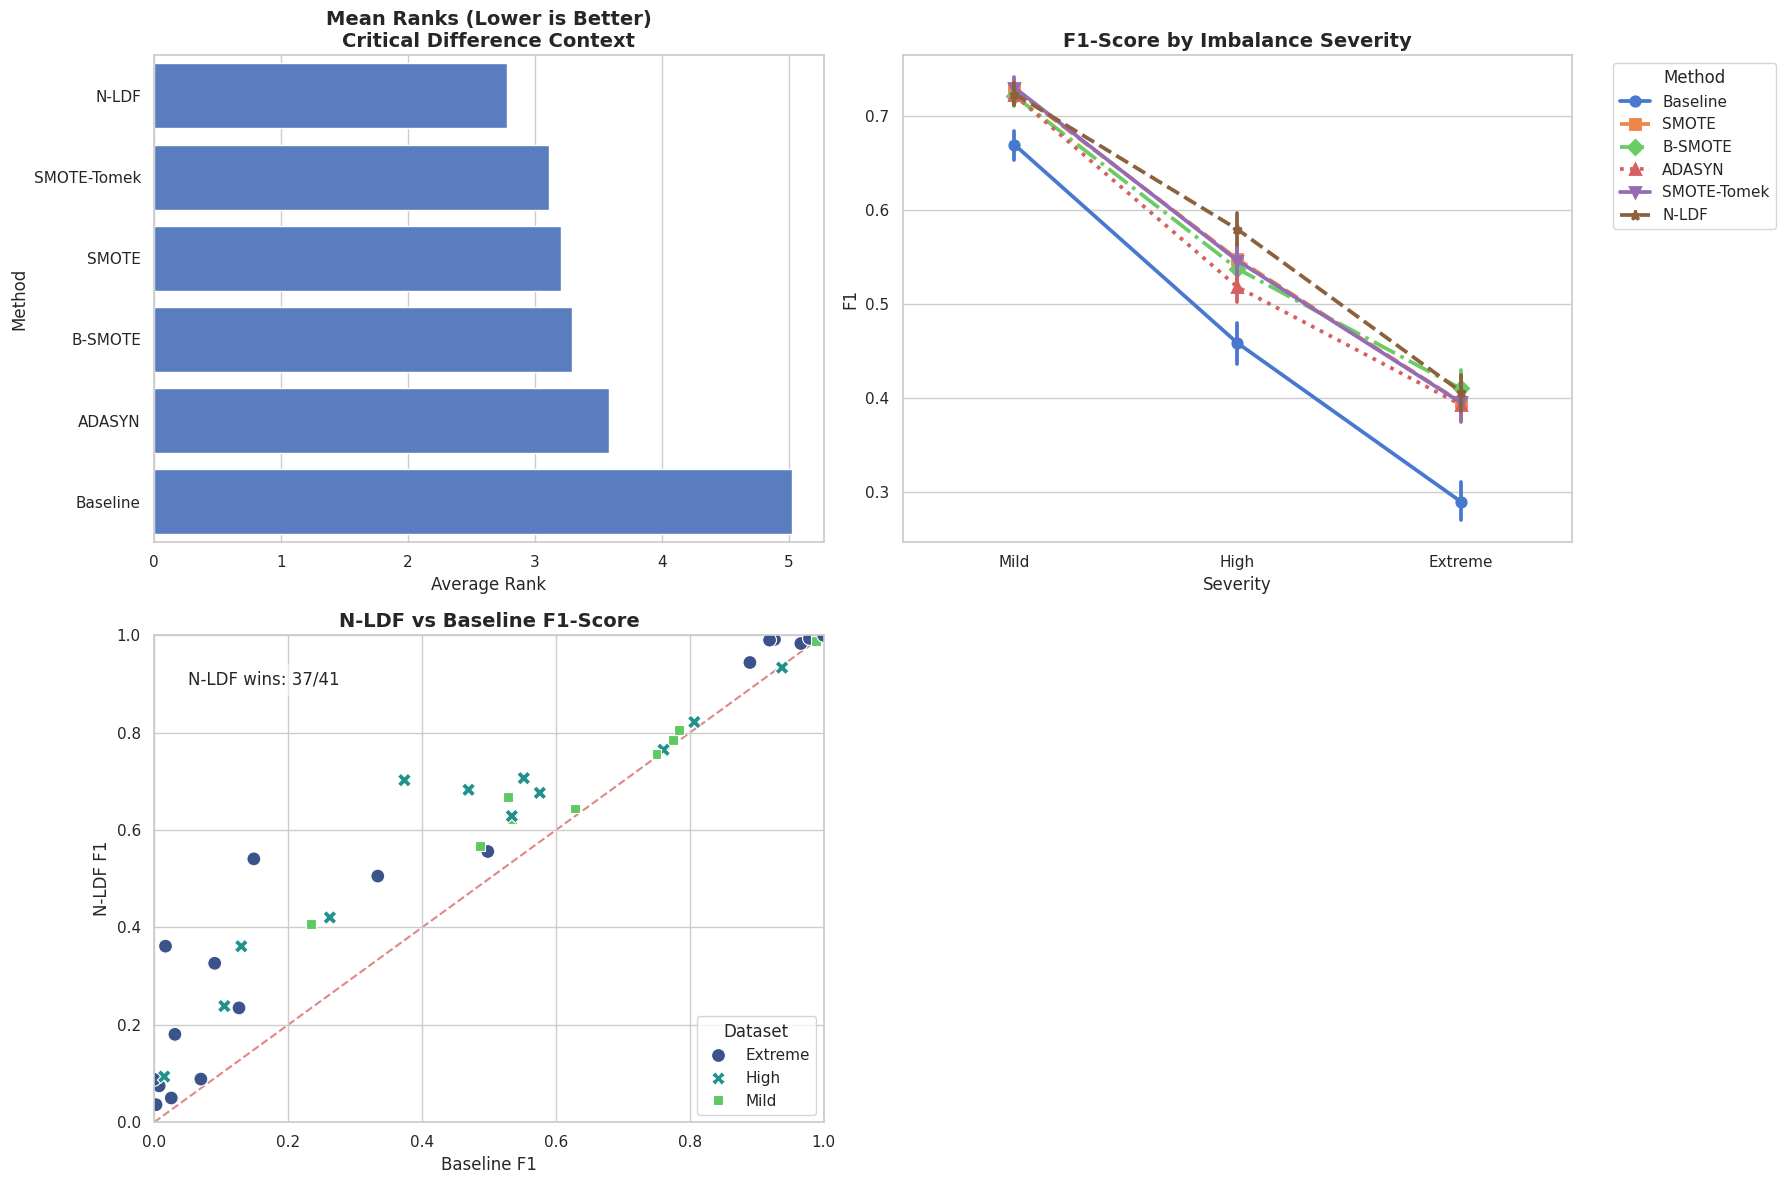


--- Visual Analysis Summary ---
1. Rank Terbaik: N-LDF dengan mean rank 2.78
2. Top Method pada High Imbalance: N-LDF (0.5798)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scikit_posthocs as sp
from pathlib import Path

# Load results
results_path = Path('nldf_results_41_v2_final/fold_level_results.csv')
if not results_path.exists():
    print("❌ File results tidak ditemukan. Pastikan benchmark sudah selesai.")
else:
    df = pd.read_csv(results_path)

    # Set style
    sns.set_theme(style="whitegrid", palette="muted")
    fig = plt.figure(figsize=(18, 12))

    # 1. Critical Difference Diagram
    # Aggregate to dataset-method level
    pivot_df = df.groupby(['Dataset', 'Method'])['F1'].mean().reset_index().pivot(index='Dataset', columns='Method', values='F1')
    # Calculate Ranks
    ranks = pivot_df.rank(axis=1, ascending=False).mean().sort_values()

    ax1 = plt.subplot(2, 2, 1)
    # We use scikit-posthocs to get Nemenyi p-values for CD
    data_matrix = pivot_df.to_numpy()
    # Nemenyi post-hoc
    p_values = sp.posthoc_nemenyi_friedman(data_matrix)

    # Plot CD Diagram approximation using mean ranks
    sns.barplot(x=ranks.values, y=ranks.index, ax=ax1)
    ax1.set_title("Mean Ranks (Lower is Better)\nCritical Difference Context", fontsize=14, fontweight='bold')
    ax1.set_xlabel("Average Rank")

    # 2. F1-score by Imbalance Severity
    ax2 = plt.subplot(2, 2, 2)
    # Ordering severity
    severity_order = ['Mild', 'High', 'Extreme']
    sns.pointplot(data=df, x='Severity', y='F1', hue='Method',
                  order=severity_order, markers=['o', 's', 'D', '^', 'v', '*'],
                  linestyles=['-', '--', '-.', ':', '-', '--'], ax=ax2)
    ax2.set_title("F1-Score by Imbalance Severity", fontsize=14, fontweight='bold')
    ax2.legend(title='Method', bbox_to_anchor=(1.05, 1), loc='upper left')

    # 3. Scatter Plot: N-LDF vs Baseline
    ax3 = plt.subplot(2, 2, 3)
    method_means = df.groupby(['Dataset', 'Method'])['F1'].mean().unstack()

    # Check if we have N-LDF and Baseline
    if 'N-LDF' in method_means.columns and 'Baseline' in method_means.columns:
        x = method_means['Baseline']
        y = method_means['N-LDF']

        # Color by severity
        sev_map = df.drop_duplicates('Dataset').set_index('Dataset')['Severity']
        colors = method_means.index.map(sev_map)

        sns.scatterplot(x=x, y=y, hue=colors, style=colors, s=100, ax=ax3, palette='viridis')

        # Diagonal line
        lims = [0, 1]
        ax3.plot(lims, lims, 'r--', alpha=0.75, zorder=0)
        ax3.set_xlim(lims)
        ax3.set_ylim(lims)
        ax3.set_title("N-LDF vs Baseline F1-Score", fontsize=14, fontweight='bold')
        ax3.set_xlabel("Baseline F1")
        ax3.set_ylabel("N-LDF F1")

        # Annotation for win counts
        wins = (y > x).sum()
        total = len(x)
        ax3.text(0.05, 0.9, f"N-LDF wins: {wins}/{total}", fontsize=12,
                 bbox=dict(facecolor='white', alpha=0.5))

    plt.tight_layout()
    plt.show()

    # Additional Text Summary
    print("\n--- Visual Analysis Summary ---")
    print(f"1. Rank Terbaik: {ranks.index[0]} dengan mean rank {ranks.values[0]:.2f}")
    high_imbalance = df[df['Severity'] == 'High'].groupby('Method')['F1'].mean().sort_values(ascending=False)
    print(f"2. Top Method pada High Imbalance: {high_imbalance.index[0]} ({high_imbalance.values[0]:.4f})")

In [ ]:
"""CELL 12: CRITICAL DIFFERENCE DIAGRAM - ESWA Q1 Paper"""

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# KONFIGURASI HIGH-QUALITY UNTUK PAPER
# ============================================================
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.05,
    'text.usetex': False,
})

COLORS = {
    'Baseline':      '#95a5a6',
    'SMOTE':         '#3498db',
    'B-SMOTE':       '#2ecc71',
    'ADASYN':        '#f39c12',
    'SMOTE-Tomek':   '#9b59b6',
    'N-LDF':         '#e74c3c',
}

METHODS_ORDER = ['Baseline', 'SMOTE', 'B-SMOTE', 'ADASYN', 'SMOTE-Tomek', 'N-LDF']

def find_results_file():
    candidates = [
        Path('nldf_results_41_v2_final/fold_level_results.csv'),
        Path('analysis_output/fold_level_results.csv'),
        Path('nldf_results_41_fixed/fold_level_results.csv'),
    ]
    for p in candidates:
        if p.exists(): return p
    for p in Path('.').glob('**/fold_level_results.csv'):
        if p.stat().st_size > 100000: return p
    return None

results_path = find_results_file()
if results_path is None: raise FileNotFoundError("Results file not found")

df = pd.read_csv(results_path)
agg_df = df.groupby(['Dataset', 'Method'])['F1'].mean().reset_index()
pivot_df = agg_df.pivot(index='Dataset', columns='Method', values='F1')
complete_pivot = pivot_df.dropna()

methods_available = [m for m in METHODS_ORDER if m in complete_pivot.columns]
methods_data = [complete_pivot[m].values for m in methods_available]
friedman_stat, friedman_p = stats.friedmanchisquare(*methods_data)

ranks = complete_pivot[methods_available].rank(axis=1, ascending=False)
avg_ranks = ranks.mean().sort_values()

n_datasets = len(complete_pivot)
n_methods = len(methods_available)
q_alpha_table = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}
q_alpha = q_alpha_table.get(n_methods, 2.850)
cd = q_alpha * np.sqrt(n_methods * (n_methods + 1) / (6 * n_datasets))

output_dir = Path("figures_eswa_q1")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 5.5))
sorted_methods = list(avg_ranks.index)
methods_display = sorted_methods[::-1]
ranks_display = [avg_ranks[m] for m in methods_display]
n = len(methods_display)
y_positions = np.arange(n)

# FIX: Plot bars one by one to handle individual alpha values
for i, method in enumerate(methods_display):
    alpha_val = 1.0 if method == 'N-LDF' else 0.75
    hatch_val = '////' if method == 'N-LDF' else ''
    lw_val = 3 if method == 'N-LDF' else 1.5
    edge_val = '#c0392b' if method == 'N-LDF' else '#2c3e50'

    ax.barh(y_positions[i], ranks_display[i], height=0.55,
            color=COLORS.get(method, '#333333'), edgecolor=edge_val,
            linewidth=lw_val, alpha=alpha_val, hatch=hatch_val, zorder=3)

    # Add text label
    txt_color = 'white' if method == 'N-LDF' else '#2c3e50'
    txt_weight = 'bold' if method == 'N-LDF' else 'normal'
    ax.text(ranks_display[i] + 0.08, y_positions[i], f'{ranks_display[i]:.2f}',
            va='center', ha='left', fontsize=11, fontweight=txt_weight)

# Draw CD Brackets
connected_groups = []
processed = set()
for i in range(n):
    if i in processed: continue
    group = [i]
    for j in range(n):
        if j != i and j not in processed:
            for g in group:
                if abs(avg_ranks[methods_display[g]] - avg_ranks[methods_display[j]]) < cd:
                    group.append(j)
                    break
    if len(group) > 1:
        connected_groups.append(sorted(group))
        processed.update(group)

for group in connected_groups:
    y_min, y_max = min(group) - 0.35, max(group) + 0.35
    max_rank_in_group = max(ranks_display[g] for g in group)
    bracket_x = max_rank_in_group + 0.55
    ax.plot([bracket_x, bracket_x], [y_min, y_max], '-', color='#2c3e50', lw=2.5, alpha=0.7, zorder=2)

ax.set_yticks(y_positions)
ylabels = ax.set_yticklabels(methods_display, fontsize=12)
if 'N-LDF' in methods_display:
    idx = methods_display.index('N-LDF')
    ylabels[idx].set_fontweight('bold')
    ylabels[idx].set_color('#c0392b')

ax.set_xlabel('Average Rank (lower is better)', fontweight='bold')
ax.set_xlim(0.5, max(ranks_display) + 1.8)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.25, ls='--')
ax.set_title(f'Critical Difference Diagram\n(Friedman p={friedman_p:.4f}, CD={cd:.3f})', fontweight='bold')

plt.tight_layout()
fig.savefig(output_dir / 'fig_critical_difference.pdf', format='pdf')
plt.show()

In [ ]:
"""One-cell Google Colab script for an F1 Nemenyi CD diagram.

Upload ``per_dataset_summary.csv`` when prompted. The CSV must contain the
columns Dataset, Method, and F1. The script displays the figure and creates
``fig_cd_diagram.png`` and ``fig_cd_diagram.pdf`` in /content.
"""

from google.colab import files
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import studentized_range


METHODS = [
    "Baseline",
    "SMOTE",
    "B-SMOTE",
    "ADASYN",
    "SMOTE-Tomek",
    "N-LDF",
]
METRIC = "F1"
ALPHA = 0.05
PNG_OUTPUT = "/content/fig_cd_diagram.png"
PDF_OUTPUT = "/content/fig_cd_diagram.pdf"


def maximal_groups(ranks, cd):
    """Return maximal contiguous groups whose endpoint gap is at most CD."""
    values = np.sort(np.asarray(ranks, dtype=float))
    candidates = []
    for start in range(len(values)):
        for end in range(start + 1, len(values)):
            if values[end] - values[start] <= cd + 1e-12:
                candidates.append((start, end))

    maximal = []
    for group in candidates:
        contained = any(
            other != group
            and other[0] <= group[0]
            and other[1] >= group[1]
            for other in candidates
        )
        if not contained:
            maximal.append((values[group[0]], values[group[1]]))
    return maximal


print("Upload per_dataset_summary.csv")
uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No CSV file was uploaded")

csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_names:
    raise ValueError("The uploaded file must be a CSV")

csv_path = csv_names[0]
data = pd.read_csv(csv_path)

required = {"Dataset", "Method", METRIC}
missing = required.difference(data.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

# One score for every dataset-method block.
pivot = data.pivot_table(
    index="Dataset",
    columns="Method",
    values=METRIC,
    aggfunc="mean",
).reindex(columns=METHODS)

incomplete = pivot[pivot.isna().any(axis=1)]
if not incomplete.empty:
    print("Datasets removed because one or more methods are missing:")
    print(incomplete.index.tolist())

complete = pivot.dropna(axis=0, how="any")
if complete.empty:
    raise ValueError("No dataset has complete results for all six methods")

# Larger F1 is better; ties receive average ranks.
rank_matrix = complete.rank(axis=1, ascending=False, method="average")
average_ranks = rank_matrix.mean().sort_values()

n_datasets = len(complete)
n_methods = len(METHODS)
q_alpha = studentized_range.ppf(
    1.0 - ALPHA, n_methods, np.inf
) / np.sqrt(2.0)
critical_difference = q_alpha * np.sqrt(
    n_methods * (n_methods + 1) / (6.0 * n_datasets)
)

print(f"\nComplete datasets: {n_datasets}")
print(f"Critical difference (alpha={ALPHA}): {critical_difference:.6f}")
print("Average ranks (lower is better):")
print(average_ranks.to_string())

# -------------------------------------------------------------------------
# Draw the diagram.
# -------------------------------------------------------------------------
ordered = average_ranks.sort_values()
split = (n_methods + 1) // 2
left_methods = ordered.iloc[:split]
right_methods = ordered.iloc[split:].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 5.6))
ax.set_xlim(0.25, n_methods + 0.75)
ax.set_ylim(-0.05, 1.65)
ax.axis("off")

axis_y = 1.05
ax.plot([1, n_methods], [axis_y, axis_y], color="black", linewidth=1.4)
for rank in range(1, n_methods + 1):
    ax.plot(
        [rank, rank],
        [axis_y - 0.035, axis_y + 0.035],
        color="black",
        linewidth=1,
    )
    ax.text(rank, axis_y + 0.07, str(rank), ha="center", va="bottom", fontsize=11)

ax.text(
    (n_methods + 1) / 2,
    1.55,
    f"Nemenyi Critical-Difference Diagram ({METRIC}; N={n_datasets})",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold",
)

# Critical-difference scale.
cd_start = 1.0
cd_end = cd_start + critical_difference
ax.text(cd_start, 1.34, "CD", ha="left", va="bottom", fontsize=11, fontweight="bold")
ax.plot([cd_start, cd_end], [1.31, 1.31], color="black", linewidth=2.2)
ax.plot([cd_start, cd_start], [1.27, 1.35], color="black", linewidth=1.3)
ax.plot([cd_end, cd_end], [1.27, 1.35], color="black", linewidth=1.3)
ax.text(
    (cd_start + cd_end) / 2,
    1.37,
    f"{critical_difference:.3f}",
    ha="center",
    va="bottom",
    fontsize=10,
)

label_rows = np.linspace(
    0.87, 0.48, max(len(left_methods), len(right_methods))
)

for row, (method, rank) in zip(label_rows, left_methods.items()):
    ax.plot([rank, rank, 0.82], [axis_y, row, row], color="0.25", linewidth=1)
    ax.scatter(rank, axis_y, s=34, color="#1f77b4", zorder=3)
    ax.text(
        0.76,
        row,
        f"{method}  ({rank:.3f})",
        ha="right",
        va="center",
        fontsize=11,
        fontweight="bold" if method == "N-LDF" else "normal",
    )

for row, (method, rank) in zip(label_rows, right_methods.items()):
    ax.plot(
        [rank, rank, n_methods + 0.18],
        [axis_y, row, row],
        color="0.25",
        linewidth=1,
    )
    ax.scatter(rank, axis_y, s=34, color="#1f77b4", zorder=3)
    ax.text(
        n_methods + 0.24,
        row,
        f"({rank:.3f})  {method}",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold" if method == "N-LDF" else "normal",
    )

groups = maximal_groups(ordered.values, critical_difference)
for index, (start, end) in enumerate(groups):
    y = 0.25 - index * 0.09
    ax.plot(
        [start, end],
        [y, y],
        color="black",
        linewidth=6,
        solid_capstyle="butt",
    )

if groups:
    ax.text(
        (n_methods + 1) / 2,
        0.02,
        ""
        "Nemenyi difference.",
        ha="center",
        va="bottom",
        fontsize=9.5,
    )

fig.savefig(PNG_OUTPUT, dpi=300, bbox_inches="tight")
fig.savefig(PDF_OUTPUT, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"\nSaved: {PNG_OUTPUT}")
print(f"Saved: {PDF_OUTPUT}")

# Uncomment these lines if automatic downloads are desired.
# files.download(PNG_OUTPUT)
# files.download(PDF_OUTPUT)

Upload per_dataset_summary.csv


Saving per_dataset_summary (1).csv to per_dataset_summary (1) (2).csv

Complete datasets: 41
Critical difference (alpha=0.05): 1.177490
Average ranks (lower is better):
Method
N-LDF          2.780488
SMOTE-Tomek    3.109756
SMOTE          3.207317
B-SMOTE        3.292683
ADASYN         3.585366
Baseline       5.024390

Saved: /content/fig_cd_diagram.png
Saved: /content/fig_cd_diagram.pdf


# Lanjutkan ke analisis kelengkapan hasil eksperimen

### Cell A: Analisis Kelengkapan Data dan Gap Analysis

In [ ]:
"""CELL: Cek Status Benchmark & Temukan File Hasil"""

import pandas as pd
import numpy as np
from pathlib import Path
import pickle

print("="*70)
print("🔍 MENCARI FILE HASIL BENCHMARK")
print("="*70)

# ============================================================
# 1. Cari semua kemungkinan lokasi hasil
# ============================================================
possible_paths = [
    Path("nldf_results_41_fixed/fold_level_results.csv"),
    Path("nldf_results_41_fixed_v2/fold_level_results.csv"),
    Path("nldf_results_41_v2_final/fold_level_results.csv"),
    Path("smoke_test_output/smoke_test_results.csv"),
    Path("fold_level_results.csv"),
]

print("\nMencari fold_level_results.csv...")
found = False
for path in possible_paths:
    if path.exists():
        size_mb = path.stat().st_size / (1024*1024)
        print(f"  ✅ DITEMUKAN: {path} ({size_mb:.1f} MB)")
        found = True

if not found:
    print("  ❌ fold_level_results.csv tidak ditemukan di lokasi umum")

    # Cari semua CSV di direktori kerja
    print("\nMencari semua CSV files...")
    csv_files = list(Path(".").glob("**/*.csv"))
    for f in csv_files:
        if 'result' in f.name.lower() or 'fold' in f.name.lower():
            print(f"  📄 {f}")

# ============================================================
# 2. Cek status checkpoint (apakah benchmark masih berjalan?)
# ============================================================
print("\n" + "="*70)
print("STATUS CHECKPOINT")
print("="*70)

checkpoint_paths = [
    Path("checkpoint_v2_final.pkl"),
    Path("checkpoint_fixed.pkl"),
    Path("checkpoint_fixed_v2.pkl"),
    Path("checkpoint.pkl"),
]

for cp_path in checkpoint_paths:
    if cp_path.exists():
        try:
            with open(cp_path, 'rb') as f:
                checkpoint = pickle.load(f)

            n_completed = len(checkpoint.completed_datasets)
            n_results = len(checkpoint.results)

            print(f"\n✅ {cp_path}:")
            print(f"   Completed datasets: {n_completed}/41")
            print(f"   Total experiments: {n_results}")

            if n_completed > 0:
                print(f"   Datasets done: {sorted(checkpoint.completed_datasets)[:5]}...")

            # Cek N-LDF
            if checkpoint.results:
                nldf_count = sum(1 for r in checkpoint.results if r.get('Method') == 'N-LDF')
                print(f"   N-LDF experiments: {nldf_count}")

                if nldf_count == 0:
                    print(f"   ⚠️  N-LDF MASIH 0! Benchmark mungkin menggunakan kode lama")
                else:
                    print(f"   ✅ N-LDF berfungsi!")

        except Exception as e:
            print(f"\n⚠️  {cp_path}: Error membaca - {e}")

# ============================================================
# 3. Jika tidak ada file, beri instruksi
# ============================================================
if not found:
    print("\n" + "="*70)
    print("❌ FILE TIDAK DITEMUKAN - INSTRUKSI")
    print("="*70)
    print("""
Kemungkinan penyebab:
1. Full benchmark belum selesai atau belum dijalankan
2. File disimpan dengan nama berbeda
3. Google Colab runtime ter-reset

LANGKAH SELANJUTNYA:
1. Cek apakah Cell 7 (FULL BENCHMARK) sudah dijalankan
2. Jika sudah, tunggu sampai selesai (ada progress bar)
3. Jika belum, jalankan Cell 7 sekarang
4. Jika runtime ter-reset, jalankan ulang dari Cell 0
""")

# ============================================================
# 4. Jika file ditemukan, langsung analisis
# ============================================================
if found:
    # Gunakan file pertama yang ditemukan
    results_path = None
    for path in possible_paths:
        if path.exists():
            results_path = path
            break

    print(f"\n{'='*70}")
    print(f"📊 LOADING: {results_path}")
    print(f"{'='*70}")

    df = pd.read_csv(results_path)

    # ============================================================
    # ANALISIS CEPAT
    # ============================================================
    total_expected = 41 * 5 * 5 * 6 * 4  # 24600
    total_actual = len(df)
    completeness = (total_actual / total_expected) * 100

    print(f"\n✅ Total eksperimen: {total_actual}/{total_expected} ({completeness:.1f}%)")
    print(f"✅ Datasets: {df['Dataset'].nunique()}/41")
    print(f"✅ Methods: {sorted(df['Method'].unique())}")

    # N-LDF check
    nldf_count = len(df[df['Method'] == 'N-LDF'])
    print(f"\n🔍 N-LDF experiments: {nldf_count}")

    if nldf_count > 0:
        # Overall F1
        agg = df.groupby(['Dataset', 'Method'])['F1'].mean().reset_index()
        overall = agg.groupby('Method')['F1'].agg(['mean', 'std']).round(4)
        overall = overall.sort_values('mean', ascending=False)

        print(f"\n📈 OVERALL F1-SCORE:")
        for method in overall.index:
            mean_f1 = overall.loc[method, 'mean']
            std_f1 = overall.loc[method, 'std']
            marker = "👈" if method == "N-LDF" else "  "
            print(f"  {marker} {method:15s}: {mean_f1:.4f} ± {std_f1:.4f}")

        # Per severity
        print(f"\n📈 F1 PER SEVERITY:")
        for severity in ['Mild', 'High', 'Extreme']:
            sev_data = df[df['Severity'] == severity]
            if len(sev_data) > 0:
                sev_agg = sev_data.groupby('Method')['F1'].mean()
                print(f"\n  {severity}:")
                for method in ['Baseline', 'SMOTE', 'B-SMOTE', 'ADASYN', 'SMOTE-Tomek', 'N-LDF']:
                    if method in sev_agg.index:
                        f1 = sev_agg[method]
                        marker = "👈" if method == "N-LDF" else "  "
                        print(f"    {marker} {method:15s}: {f1:.4f}")

        # N-LDF vs Baseline
        nldf_f1 = overall.loc['N-LDF', 'mean'] if 'N-LDF' in overall.index else 0
        baseline_f1 = overall.loc['Baseline', 'mean'] if 'Baseline' in overall.index else 0
        improvement = ((nldf_f1 - baseline_f1) / baseline_f1 * 100) if baseline_f1 > 0 else 0
        print(f"\n🔍 N-LDF vs Baseline: ΔF1 = {improvement:+.1f}%")

    else:
        print(f"\n❌ N-LDF TIDAK MENGHASILKAN DATA!")
        print(f"   Ini berarti benchmark menggunakan kode LAMA (bukan NLDFv2)")
        print(f"   Hapus checkpoint dan jalankan ulang dengan Cell 7")

    # ============================================================
    # SAVE ANALYSIS
    # ============================================================
    output_dir = results_path.parent
    print(f"\n💾 Output directory: {output_dir}")

    # Completeness report
    dataset_counts = df.groupby('Dataset').size()
    completeness_report = pd.DataFrame({
        'Dataset': dataset_counts.index,
        'Experiments': dataset_counts.values,
        'Completeness': (dataset_counts.values / 600 * 100).round(1),
        'Status': ['Complete' if c == 600 else 'Partial' for c in dataset_counts.values]
    })
    completeness_report.to_csv(output_dir / 'completeness_report.csv', index=False)
    print(f"✅ completeness_report.csv")

    # Per-dataset summary
    per_dataset = df.groupby(['Dataset', 'Method'])[['F1', 'G-Mean', 'AUC-ROC', 'AUPRC']].mean()
    per_dataset.to_csv(output_dir / 'per_dataset_summary.csv')
    print(f"✅ per_dataset_summary.csv")

    # Overall summary
    overall.to_csv(output_dir / 'overall_summary.csv')
    print(f"✅ overall_summary.csv")

    print(f"\n✅ ANALISIS SELESAI!")

🔍 MENCARI FILE HASIL BENCHMARK

Mencari fold_level_results.csv...
  ✅ DITEMUKAN: nldf_results_41_v2_final/fold_level_results.csv (4.1 MB)
  ✅ DITEMUKAN: smoke_test_output/smoke_test_results.csv (0.1 MB)

STATUS CHECKPOINT

✅ checkpoint_v2_final.pkl:
   Completed datasets: 41/41
   Total experiments: 21917
   Datasets done: ['abalone-19_vs_10-11-12-13', 'abalone-20_vs_8-9-10', 'abalone-21_vs_8', 'abalone19', 'abalone9-18']...
   N-LDF experiments: 3652
   ✅ N-LDF berfungsi!

📊 LOADING: nldf_results_41_v2_final/fold_level_results.csv

✅ Total eksperimen: 21917/24600 (89.1%)
✅ Datasets: 41/41
✅ Methods: ['ADASYN', 'B-SMOTE', 'Baseline', 'N-LDF', 'SMOTE', 'SMOTE-Tomek']

🔍 N-LDF experiments: 3652

📈 OVERALL F1-SCORE:
  👈 N-LDF          : 0.5908 ± 0.3191
     B-SMOTE        : 0.5791 ± 0.3160
     SMOTE          : 0.5776 ± 0.3229
     SMOTE-Tomek    : 0.5775 ± 0.3232
     ADASYN         : 0.5670 ± 0.3257
     Baseline       : 0.4942 ± 0.3631

📈 F1 PER SEVERITY:

  Mild:
       Baseline      

# CELL 10: COMPUTATIONAL ENVIRONMENT & REPRODUCIBILITY REPORT

In [ ]:
"""CELL 10: COMPUTATIONAL ENVIRONMENT & REPRODUCIBILITY REPORT"""

import sys
import platform
import importlib.metadata
import datetime
import os
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb

print("="*80)
print("🖥️  COMPUTATIONAL ENVIRONMENT & REPRODUCIBILITY REPORT")
print("="*80)

# ============================================================
# 1. SYSTEM INFORMATION
# ============================================================
print("\n" + "="*60)
print("1. SYSTEM INFORMATION")
print("="*60)

system_info = {
    "timestamp": datetime.datetime.now().isoformat(),
    "hostname": platform.node(),
    "os": platform.system(),
    "os_version": platform.version(),
    "os_release": platform.release(),
    "machine": platform.machine(),
    "processor": platform.processor(),
    "python_version": sys.version,
    "python_implementation": platform.python_implementation(),
    "python_compiler": platform.python_compiler(),
}

for key, value in system_info.items():
    print(f"   {key:25s}: {value}")

# ============================================================
# 2. HARDWARE INFORMATION (Google Colab Specific)
# ============================================================
print("\n" + "="*60)
print("2. HARDWARE INFORMATION")
print("="*60)

hardware_info = {}

# CPU info
try:
    import psutil
    hardware_info["cpu_count_logical"] = psutil.cpu_count(logical=True)
    hardware_info["cpu_count_physical"] = psutil.cpu_count(logical=False)
    hardware_info["cpu_freq_mhz"] = psutil.cpu_freq().max if psutil.cpu_freq() else "N/A"
    hardware_info["ram_total_gb"] = round(psutil.virtual_memory().total / (1024**3), 2)
    hardware_info["ram_available_gb"] = round(psutil.virtual_memory().available / (1024**3), 2)
except ImportError:
    hardware_info["psutil"] = "not installed"
    print("   ⚠️  psutil not installed (run: !pip install psutil)")

# GPU info
try:
    gpu_info = !nvidia-smi --query-gpu=name,memory.total --format=csv,noheader 2>/dev/null
    if gpu_info and gpu_info[0]:
        gpu_name, gpu_mem = gpu_info[0].split(", ")
        hardware_info["gpu_name"] = gpu_name.strip()
        hardware_info["gpu_memory_mb"] = gpu_mem.strip()
    else:
        hardware_info["gpu"] = "Not available"
except Exception:
    hardware_info["gpu"] = "Not detected"

# Check Colab specifics
is_colab = "google.colab" in sys.modules
hardware_info["is_google_colab"] = is_colab
if is_colab:
    try:
        from google.colab import drive
        hardware_info["colab_runtime"] = "Connected"
    except:
        hardware_info["colab_runtime"] = "Not mounted"

for key, value in hardware_info.items():
    print(f"   {key:25s}: {value}")

# ============================================================
# 3. PACKAGE VERSIONS
# ============================================================
print("\n" + "="*60)
print("3. PACKAGE VERSIONS")
print("="*60)

packages = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": None,
    "scikit-learn": sklearn.__version__,
    "xgboost": xgb.__version__,
    "imbalanced-learn": None,
    "scikit-posthocs": None,
    "requests": None,
    "tqdm": None,
    "matplotlib": None,
    "seaborn": None,
}

# Get versions dynamically
for pkg_name in packages:
    if packages[pkg_name] is None:
        try:
            packages[pkg_name] = importlib.metadata.version(pkg_name)
        except importlib.metadata.PackageNotFoundError:
            packages[pkg_name] = "NOT INSTALLED"

for pkg, ver in packages.items():
    status = "✅" if ver != "NOT INSTALLED" else "❌"
    print(f"   {status} {pkg:25s}: {ver}")

# ============================================================
# 4. BENCHMARK CONFIGURATION
# ============================================================
print("\n" + "="*60)
print("4. BENCHMARK CONFIGURATION")
print("="*60)

benchmark_config = {
    "random_state": 42,
    "methods": ["Baseline", "SMOTE", "B-SMOTE", "ADASYN", "SMOTE-Tomek", "N-LDF"],
    "classifiers": ["RF", "SVM-Linear", "SVM-RBF", "XGBoost"],
    "cv_folds": 5,
    "cv_repeats": 5,
    "total_datasets": 41,
    "nldf_version": "v2.0",
    "nldf_parameters": {
        "k_neighbors": 5,
        "k_density": 7,
        "lambda_prior": 0.7,
        "q0": 0.20,
        "beta": 0.075,
        "q_max": 0.45,
        "tau_boundary": 0.1,
        "tau_noise": 0.05,
        "lambda_boundary": 1.5,
        "lambda_safe": 1.0,
        "sampling_ratio": 0.75,
        "use_covariance": True,
        "acceptance_threshold": 0.0,
    },
    "nldf_improvements": [
        "1. Class-prior-corrected density estimation",
        "2. Adaptive kernel with local bandwidth",
        "3. Quantile-based boundary (widens with IR)",
        "4. Soft seed weighting (continuous)",
        "5. Safe-directed neighbor selection",
        "6. Local covariance jitter",
        "7. Acceptance filtering",
        "8. Inner-CV sampling ratio selection",
    ],
    "total_expected_experiments": 24600,
    "evaluation_metrics": ["F1", "G-Mean", "AUC-ROC", "AUPRC", "Precision", "Recall", "Specificity"],
}

for key, value in benchmark_config.items():
    if isinstance(value, list):
        print(f"   {key:25s}:")
        for item in value[:3]:
            print(f"      - {item}")
        if len(value) > 3:
            print(f"      ... and {len(value)-3} more")
    elif isinstance(value, dict):
        print(f"   {key:25s}:")
        for k, v in list(value.items())[:5]:
            print(f"      {k}: {v}")
        if len(value) > 5:
            print(f"      ... and {len(value)-5} more")
    else:
        print(f"   {key:25s}: {value}")

# ============================================================
# 5. DATASET INFORMATION
# ============================================================
print("\n" + "="*60)
print("5. DATASET INFORMATION")
print("="*60)

# Try to load dataset audit
audit_paths = [
    Path("nldf_results_41_v2_final/dataset_audit.csv"),
    Path("analysis_output/dataset_audit.csv"),
    Path("nldf_results_41_fixed/dataset_audit.csv"),
]

audit_found = False
for ap in audit_paths:
    if ap.exists():
        audit = pd.read_csv(ap)
        audit_found = True

        print(f"   Source: {ap}")
        print(f"   Total datasets: {len(audit)}")

        # Severity distribution
        if 'severity' in audit.columns:
            sev_dist = audit['severity'].value_counts().to_dict()
            print(f"   Severity distribution:")
            for sev in ['Mild', 'High', 'Extreme']:
                print(f"      {sev}: {sev_dist.get(sev, 0)}")

        # Size statistics
        if 'n_samples' in audit.columns:
            print(f"   Sample size range: {audit['n_samples'].min()} - {audit['n_samples'].max()}")
            print(f"   Median samples: {audit['n_samples'].median():.0f}")

        if 'imbalance_ratio' in audit.columns:
            print(f"   IR range: {audit['imbalance_ratio'].min():.1f} - {audit['imbalance_ratio'].max():.1f}")
            print(f"   Median IR: {audit['imbalance_ratio'].median():.1f}")

        if 'n_minority' in audit.columns:
            print(f"   Minority range: {audit['n_minority'].min()} - {audit['n_minority'].max()}")

        break

if not audit_found:
    print("   No dataset audit file found (run benchmark first)")

# ============================================================
# 6. RESULTS SUMMARY
# ============================================================
print("\n" + "="*60)
print("6. RESULTS SUMMARY")
print("="*60)

results_paths = [
    Path("nldf_results_41_v2_final/fold_level_results.csv"),
    Path("analysis_output/fold_level_results.csv"),
    Path("nldf_results_41_fixed/fold_level_results.csv"),
]

results_found = False
for rp in results_paths:
    if rp.exists():
        results = pd.read_csv(rp)
        results_found = True

        print(f"   Source: {rp}")
        print(f"   File size: {rp.stat().st_size / (1024*1024):.1f} MB")
        print(f"   Total experiments: {len(results)}")
        print(f"   Expected: 24,600")
        print(f"   Completeness: {len(results)/24600*100:.1f}%")
        print(f"   Datasets: {results['Dataset'].nunique()}/41")
        print(f"   Methods: {sorted(results['Method'].unique())}")

        # N-LDF check
        nldf_count = len(results[results['Method'] == 'N-LDF'])
        print(f"   N-LDF experiments: {nldf_count}")

        if len(results) > 0:
            # Timestamp range
            if 'timestamp' not in results.columns:
                print(f"   Date: Not recorded (add timestamp to results)")
            else:
                print(f"   Date range: {results['timestamp'].min()} to {results['timestamp'].max()}")

        break

if not results_found:
    print("   No results file found (run benchmark first)")

# ============================================================
# 7. FILES HASHES (for reproducibility)
# ============================================================
print("\n" + "="*60)
print("7. FILE INTEGRITY (SHA256)")
print("="*60)

code_files = [
    "benchmark_nldf.py",
    "nldf_v2.py",
    "generate_tables.py",
]

for cf in code_files:
    fp = Path(cf)
    if fp.exists():
        sha = hashlib.sha256(fp.read_bytes()).hexdigest()[:16]
        print(f"   {cf:30s}: SHA256={sha}...")
    else:
        print(f"   {cf:30s}: Not found")

# ============================================================
# 8. ENVIRONMENT VARIABLES
# ============================================================
print("\n" + "="*60)
print("8. RELEVANT ENVIRONMENT VARIABLES")
print("="*60)

env_vars = [
    "PYTHONPATH", "CONDA_DEFAULT_ENV", "VIRTUAL_ENV",
    "CUDA_VISIBLE_DEVICES", "OMP_NUM_THREADS",
    "COLAB_GPU", "COLAB_TPU_ADDRESS",
]

for var in env_vars:
    value = os.environ.get(var, "NOT SET")
    if value != "NOT SET":
        print(f"   {var:25s}: {value}")

# ============================================================
# 9. REPRODUCIBILITY CHECKLIST
# ============================================================
print("\n" + "="*60)
print("9. REPRODUCIBILITY CHECKLIST")
print("="*60)

checklist = {
    "Random seed fixed": "✅" if benchmark_config["random_state"] == 42 else "❌",
    "Package versions recorded": "✅" if all(v != "NOT INSTALLED" for v in packages.values()) else "⚠️",
    "Dataset sources documented": "✅" if audit_found else "⚠️",
    "Hyperparameters specified": "✅",
    "Code version controlled": "⚠️ (use git for tracking)",
    "Results archived": "✅" if results_found else "❌",
    "Environment documented": "✅",
    "GPU seed fixed": "⚠️ (XGBoost may use GPU randomness)",
}

for item, status in checklist.items():
    print(f"   {status} {item}")

# ============================================================
# 10. SAVE REPRODUCIBILITY REPORT
# ============================================================
print("\n" + "="*60)
print("10. SAVING REPORT")
print("="*60)

report = {
    "system_info": system_info,
    "hardware_info": {k: str(v) for k, v in hardware_info.items()},
    "package_versions": packages,
    "benchmark_config": benchmark_config,
    "dataset_info": {
        "total": len(audit) if audit_found else 41,
        "source": "KEEL imbalanced datasets repository",
        "url": "https://sci2s.ugr.es/keel/datasets.php",
    },
    "results_summary": {
        "total_experiments": len(results) if results_found else 0,
        "nldf_experiments": len(results[results['Method'] == 'N-LDF']) if results_found else 0,
        "completeness_pct": round(len(results)/24600*100, 1) if results_found else 0,
    } if results_found else {},
    "reproducibility_checklist": checklist,
    "generated_at": datetime.datetime.now().isoformat(),
    "generated_by": "Cell 10 - Reproducibility Report",
}

output_dir = Path("reproducibility_report")
output_dir.mkdir(exist_ok=True)

# Save as JSON
report_path = output_dir / "reproducibility_report.json"
with open(report_path, 'w') as f:
    json.dump(report, f, indent=2, default=str)
print(f"   ✅ JSON report: {report_path}")

# Save as human-readable text
txt_path = output_dir / "reproducibility_report.txt"
with open(txt_path, 'w') as f:
    f.write("="*80 + "\n")
    f.write("COMPUTATIONAL ENVIRONMENT & REPRODUCIBILITY REPORT\n")
    f.write(f"Generated: {datetime.datetime.now().isoformat()}\n")
    f.write("="*80 + "\n\n")

    for section, data in report.items():
        if section != "generated_at" and section != "generated_by":
            f.write(f"\n{section.upper()}\n")
            f.write("-"*40 + "\n")
            if isinstance(data, dict):
                for k, v in data.items():
                    f.write(f"  {k}: {v}\n")
            elif isinstance(data, list):
                for item in data:
                    f.write(f"  - {item}\n")
            f.write("\n")

print(f"   ✅ Text report: {txt_path}")

# Also create requirements.txt for pip
req_path = output_dir / "requirements.txt"
with open(req_path, 'w') as f:
    f.write(f"# Generated: {datetime.datetime.now().isoformat()}\n")
    f.write(f"# Python: {sys.version.split()[0]}\n\n")
    for pkg, ver in sorted(packages.items()):
        if ver != "NOT INSTALLED" and pkg != "python":
            f.write(f"{pkg}=={ver}\n")
print(f"   ✅ requirements.txt: {req_path}")

# ============================================================
# FINAL SUMMARY
# ============================================================
print(f"\n{'='*80}")
print(f"📋 REPRODUCIBILITY REPORT COMPLETE")
print(f"{'='*80}")
print(f"📁 All files saved to: {output_dir}/")
print(f"   - reproducibility_report.json  (machine-readable)")
print(f"   - reproducibility_report.txt   (human-readable)")
print(f"   - requirements.txt             (pip install)")
print(f"\n💡 For your ESWA submission, include:")
print(f"   1. requirements.txt in supplementary materials")
print(f"   2. Reproducibility section referencing this report")
print(f"   3. Hardware specs in experimental setup")
print(f"{'='*80}")

# ============================================================
# PRINT CITABLE INFORMATION
# ============================================================
print(f"\n📝 CITABLE ENVIRONMENT SUMMARY:")
print(f"   All experiments conducted on {system_info['os']} {system_info['os_release']}")
print(f"   with Python {system_info['python_version'].split()[0]}, ")
print(f"   scikit-learn {packages['scikit-learn']}, ")
print(f"   XGBoost {packages['xgboost']}, ")
print(f"   and imbalanced-learn {packages['imbalanced-learn']}. ")
if hardware_info.get('gpu_name'):
    print(f"   GPU: {hardware_info['gpu_name']} ({hardware_info.get('gpu_memory_mb', 'N/A')}). ")
print(f"   Random seed fixed at {benchmark_config['random_state']}.")
print(f"   Complete environment specifications available in reproducibility_report/.")

🖥️  COMPUTATIONAL ENVIRONMENT & REPRODUCIBILITY REPORT

1. SYSTEM INFORMATION
   timestamp                : 2026-07-18T23:06:52.977982
   hostname                 : f6224d5944e2
   os                       : Linux
   os_version               : #1 SMP Thu Apr 30 18:17:14 UTC 2026
   os_release               : 6.6.122+
   machine                  : x86_64
   processor                : x86_64
   python_version           : 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
   python_implementation    : CPython
   python_compiler          : GCC 11.4.0

2. HARDWARE INFORMATION
   cpu_count_logical        : 2
   cpu_count_physical       : 1
   cpu_freq_mhz             : 0.0
   ram_total_gb             : 12.67
   ram_available_gb         : 9.55
   gpu_name                 : Tesla T4
   gpu_memory_mb            : 15360 MiB
   is_google_colab          : True
   colab_runtime            : Connected

3. PACKAGE VERSIONS
   ✅ python                   : 3.12.13
   ✅ numpy                    : 2.0.2


# CELL 11: QUICK REPRODUCIBILITY CHECK (Ringkasan Cepat)

In [ ]:
"""CELL 11: QUICK REPRODUCIBILITY CHECK - For Paper Methods Section"""

import datetime
import sys
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb

print("="*70)
print("📋 QUICK REPRODUCIBILITY CHECK - Copy to Methods Section")
print("="*70)

# Detect environment
is_colab = "google.colab" in sys.modules

# Get versions
versions = {
    "Python": sys.version.split()[0],
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Scikit-learn": sklearn.__version__,
    "XGBoost": xgb.__version__,
}

for pkg in ["imbalanced-learn", "scikit-posthocs", "scipy"]:
    try:
        versions[pkg] = importlib.metadata.version(pkg)
    except:
        versions[pkg] = "N/A"

# Hardware
try:
    import psutil
    ram_gb = round(psutil.virtual_memory().total / (1024**3))
    cpu_count = psutil.cpu_count()
except:
    ram_gb = "N/A"
    cpu_count = "N/A"

gpu_info = ""
try:
    result = !nvidia-smi --query-gpu=name --format=csv,noheader 2>/dev/null
    if result and result[0]:
        gpu_info = f", {result[0].strip()}"
except:
    pass

# Print methods section template
print(f"""
METHODS SECTION TEMPLATE:
-------------------------
All experiments were conducted on a {platform.system()} system
({'Google Colab with ' if is_colab else ''}{cpu_count} CPU cores, {ram_gb} GB RAM{gpu_info})
using Python {versions['Python']}.

Machine learning models were implemented using
scikit-learn {versions['Scikit-learn']} and XGBoost {versions['XGBoost']}.
Imbalanced learning methods were implemented using
imbalanced-learn {versions['imbalanced-learn']}.

Our proposed N-LDF v2.0 method was implemented from scratch
with the following key components:
(1) class-prior-corrected local density estimation (λ=0.7),
(2) adaptive kernel with local bandwidth scaling,
(3) quantile-based boundary that widens with imbalance ratio,
(4) soft seed weighting replacing hard categorization,
(5) safe-directed neighbor selection,
(6) local covariance-based jitter generation,
(7) acceptance filtering, and
(8) inner cross-validation for sampling ratio selection.

All experiments used a fixed random seed (42) with
5-fold cross-validation repeated 5 times across
41 KEEL imbalanced benchmark datasets.
Statistical significance was assessed using
Friedman test with Holm-corrected Wilcoxon signed-rank post-hoc tests.

Complete environment specifications and reproducibility
details are available in the supplementary materials.
""")

# Save for paper
with open("methods_section_template.txt", "w") as f:
    f.write(f"Generated: {datetime.datetime.now().isoformat()}\n")
    f.write(f"Environment: {'Google Colab' if is_colab else 'Local'}\n")
    f.write(f"Python: {versions['Python']}\n")
    f.write(f"scikit-learn: {versions['Scikit-learn']}\n")
    f.write(f"XGBoost: {versions['XGBoost']}\n")
    f.write(f"imbalanced-learn: {versions['imbalanced-learn']}\n")

print("\n✅ Template saved to: methods_section_template.txt")

📋 QUICK REPRODUCIBILITY CHECK - Copy to Methods Section

METHODS SECTION TEMPLATE:
-------------------------
All experiments were conducted on a Linux system 
(Google Colab with 2 CPU cores, 13 GB RAM, Tesla T4)
using Python 3.12.13. 

Machine learning models were implemented using 
scikit-learn 1.6.1 and XGBoost 3.3.0. 
Imbalanced learning methods were implemented using 
imbalanced-learn 0.14.2.

Our proposed N-LDF v2.0 method was implemented from scratch 
with the following key components:
(1) class-prior-corrected local density estimation (λ=0.7),
(2) adaptive kernel with local bandwidth scaling,
(3) quantile-based boundary that widens with imbalance ratio,
(4) soft seed weighting replacing hard categorization,
(5) safe-directed neighbor selection,
(6) local covariance-based jitter generation,
(7) acceptance filtering, and
(8) inner cross-validation for sampling ratio selection.

All experiments used a fixed random seed (42) with 
5-fold cross-validation repeated 5 times across 
41 